# Workforce Intelligence 

# 1. Import Libraries

In [1]:
# ============================================================
# WORKFORCE INTELLIGENCE — IMPORTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import defaultdict

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data"
DATA_CLEAN_DIR = PROJECT_ROOT / "data_clean"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Data directory:", DATA_DIR.resolve())
print("Clean data directory:", DATA_CLEAN_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

Project root: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine
Data directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/data
Clean data directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/data_clean
Output directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/outputs


# 2. Load Workforce Data

In [3]:
# ============================================================
# LOAD WORKFORCE DATA
# ============================================================

employees = pd.read_csv( DATA_CLEAN_DIR/ "employees_clean.csv" )

availability = pd.read_csv( DATA_CLEAN_DIR / "employee_availability_clean.csv" )

shifts = pd.read_csv( DATA_CLEAN_DIR / "shifts_clean.csv" )

daily_model = pd.read_csv( DATA_CLEAN_DIR / "daily_model_table_clean.csv", parse_dates=["date"] )

print("Employees:", employees.shape)
print("Availability:", availability.shape)
print("Shifts:", shifts.shape)
print("Daily model:", daily_model.shape)

Employees: (30, 8)
Availability: (210, 5)
Shifts: (8696, 8)
Daily model: (731, 29)


In [4]:
# ============================================================
# WORKFORCE DATA — INITIAL INSPECTION
# ============================================================

print("\nEmployees")
display(employees.head())

print("\nEmployee availability")
display(availability.head())

print("\nHistorical shifts")
display(shifts.head())

print("\ndaily_models")
display(daily_model.head())


Employees


,employee_id,employee_name,role,employment_type,hourly_cost,employment_start,employment_end,employment_status
0,E001,Clara Krause,Restaurant Manager,Full-time,25.00,2020-02-18,NaN,Active
1,E002,Piotr Lange,Restaurant Manager,Full-time,24.50,2021-07-31,NaN,Active
2,E003,Carla Schmitt,Assistant Manager,Full-time,21.00,2023-06-25,NaN,Active
3,E004,Giulia Kowalski,Assistant Manager,Full-time,19.50,2020-11-16,NaN,Active
4,E005,Katarina Fischer,Chef,Full-time,20.50,2021-12-09,NaN,Active



Employee availability


,employee_id,day_of_week_num,day_of_week,availability_status,max_hours
0,E001,1,Monday,Unavailable,0.00
1,E001,2,Tuesday,Unavailable,0.00
2,E001,3,Wednesday,Available,8.00
3,E001,4,Thursday,Available,8.00
4,E001,5,Friday,Available,8.00



Historical shifts


,shift_id,employee_id,shift_date,shift_type,start_time,end_time,hours_worked,labour_cost
0,S000001,E008,2024-01-01,Lunch,10:30,16:00,5.50,107.25
1,S000002,E016,2024-01-01,Lunch,10:30,16:00,5.50,82.50
2,S000003,E019,2024-01-01,Lunch,10:30,16:00,5.50,82.50
3,S000004,E002,2024-01-01,Full,11:30,20:00,8.00,196.00
4,S000005,E007,2024-01-01,Dinner,16:30,23:00,6.50,133.25



daily_models


,date,revenue,orders,average_order_value,orders_lunch,orders_afternoon,orders_dinner,orders_dine_in,orders_delivery,orders_takeaway,drink_revenue,day_of_week,day_of_week_num,month,month_name,quarter,week_of_year,is_weekend,restaurant_peak_day,restaurant_day_type,holiday_name,is_holiday,temperature_avg_c,temp_max_c,temp_min_c,precipitation_mm,is_rainy,weather_condition,is_promo_day
0,2024-01-01,"1,396.30",40,34.91,16,0,24,23,12,5,229.10,Monday,1,1,January,1,1,False,0,Quiet,New Year's Day,True,3.80,7.00,1.30,1.30,True,Rain,False
1,2024-01-02,"2,118.00",56,37.82,24,6,26,30,20,6,353.40,Tuesday,2,1,January,1,1,False,0,Quiet,NaN,False,1.30,3.60,-0.50,0.00,False,Cold,False
2,2024-01-03,"1,527.30",50,30.55,16,2,32,23,15,12,278.80,Wednesday,3,1,January,1,1,False,0,Quiet,NaN,False,3.40,5.30,1.90,7.00,True,Rain,False
3,2024-01-04,"2,532.30",67,37.80,20,1,46,41,17,9,473.00,Thursday,4,1,January,1,1,False,0,Medium,NaN,False,5.70,6.80,4.80,1.00,True,Rain,False
4,2024-01-05,"3,420.70",91,37.59,21,11,59,52,31,8,637.90,Friday,5,1,January,1,1,False,1,Peak,NaN,False,-0.10,1.30,-1.20,3.30,True,Rain,False


# 3. Data Cleaning and Exploration

In [5]:
# ============================================================
# DATA CLEANING
# ============================================================

employees["employment_start"] = pd.to_datetime(employees["employment_start"])

employees["employment_end"] = pd.to_datetime(employees["employment_end"], errors="coerce")

availability["day_of_week_num"] = pd.to_numeric(availability["day_of_week_num"], errors="coerce").astype(int)

availability["max_hours"] = pd.to_numeric(availability["max_hours"], errors="coerce")

shifts["shift_date"] = pd.to_datetime(shifts["shift_date"])

shifts["hours_worked"] = pd.to_numeric(shifts["hours_worked"], errors="coerce")

shifts["labour_cost"] = pd.to_numeric(shifts["labour_cost"], errors="coerce")

daily_model["orders"] = pd.to_numeric(daily_model["orders"], errors="coerce")

daily_model["revenue"] = pd.to_numeric(daily_model["revenue"], errors="coerce")

print("Cleaning completed.")

Cleaning completed.


In [6]:
# ============================================================
# WORKFORCE OVERVIEW
# ============================================================

print("Total employees:", len(employees))

print( "Active employees:", (employees["employment_status"] == "Active").sum() )

print( "Employees who left:", (employees["employment_status"] == "Left").sum() )

print( "Historical shifts:", len(shifts) )

print( "Total historical labour cost:", f"€{shifts['labour_cost'].sum():,.2f}" )

Total employees: 30
Active employees: 26
Employees who left: 4
Historical shifts: 8696
Total historical labour cost: €923,443.75


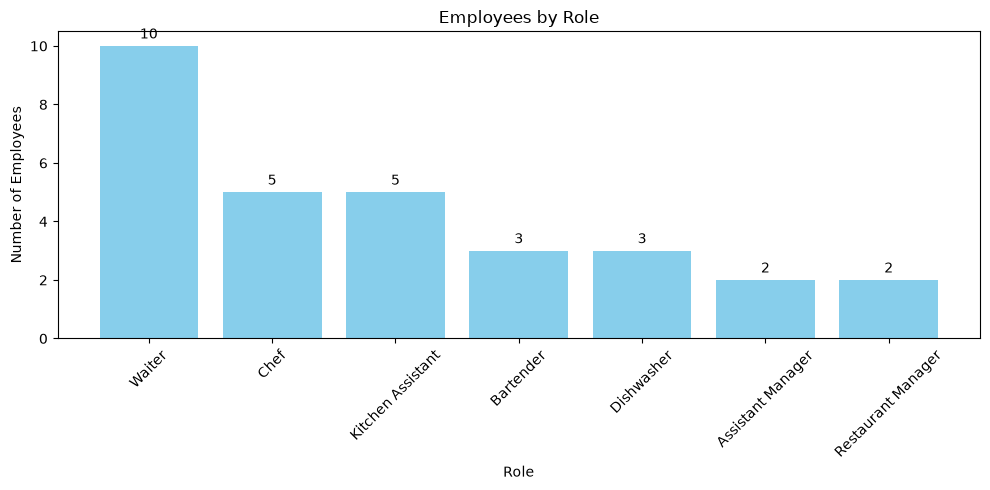

In [7]:
# ============================================================
# EMPLOYEES BY ROLE
# ============================================================

role_summary = (
    employees
    .groupby("role")
    .agg(
        employees=("employee_id", "count"),
        average_hourly_cost=("hourly_cost", "mean"),
        min_hourly_cost=("hourly_cost", "min"),
        max_hourly_cost=("hourly_cost", "max")
    )
    .reset_index()
    .sort_values("employees", ascending=False)
)

# ============================================================
# PLOT EMPLOYEES BY ROLE
# ============================================================
plt.figure(figsize=(10, 5))
bars = plt.bar(role_summary["role"], role_summary["employees"], color="skyblue")
plt.bar_label(bars, padding=3)
plt.xlabel("Role")
plt.ylabel("Number of Employees")
plt.title("Employees by Role")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Number of Employees by Employment Type')

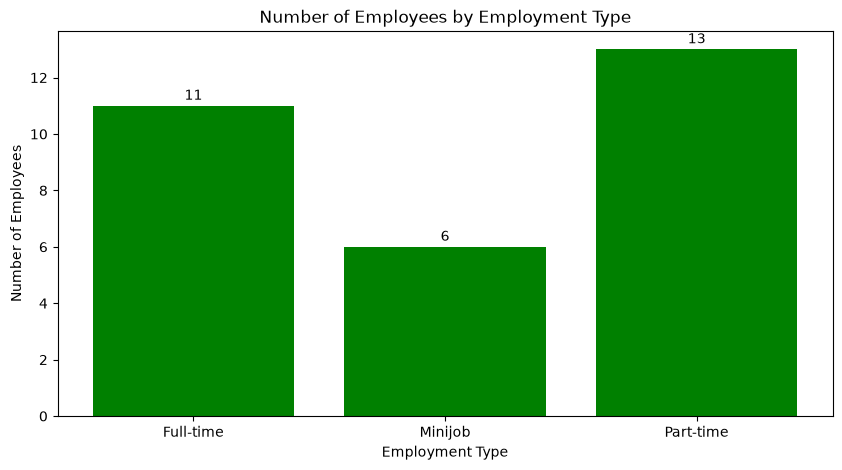

In [8]:
# ============================================================
# EMPLOYEES BY EMPLOYMENT TYPE
# ============================================================

employment_summary = (
    employees
    .groupby("employment_type")
    .agg(
        employees=("employee_id", "count"),
        average_hourly_cost=("hourly_cost", "mean")
    )
    .reset_index()
)

# ============================================================
# PLOT EMPLOYEES BY EMPLOYMENT TYPE
# ============================================================
plt.figure(figsize=(10, 5))
bars = plt.bar(employment_summary["employment_type"], employment_summary["employees"],color="green")
plt.xlabel("Employment Type")
plt.bar_label(bars, padding=2)
plt.ylabel("Number of Employees")
plt.title("Number of Employees by Employment Type")

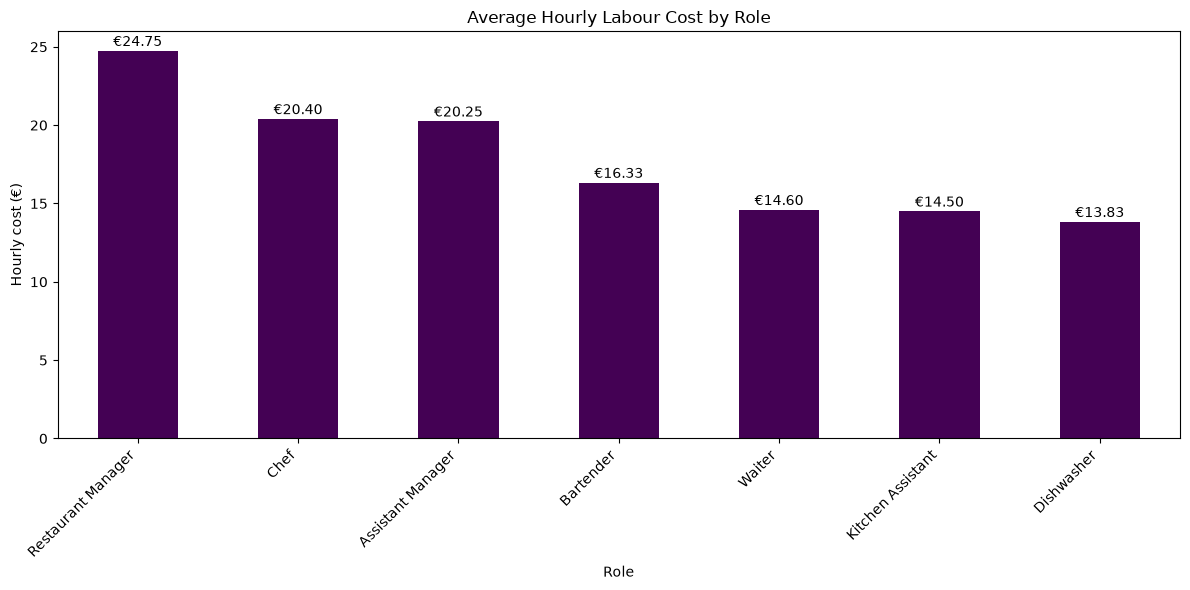

In [9]:
# ============================================================
# WORKFORCE COST STRUCTURE
# ============================================================

role_cost = ( employees .groupby("role")["hourly_cost"] .mean() .sort_values(ascending=False) )

plt.figure(figsize=(12, 6))

role_cost.plot(kind="bar", colormap="viridis")

plt.title("Average Hourly Labour Cost by Role")
plt.xlabel("Role")
plt.ylabel("Hourly cost (€)")
plt.xticks(rotation=45, ha="right")
plt.bar_label(plt.gca().containers[0], fmt="€%.2f", padding=1)
plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# HISTORICAL SHIFT ANALYSIS
# ============================================================

daily_shifts = (
    shifts
    .groupby("shift_date")
    .agg(
        employees_scheduled=("employee_id", "nunique"),
        total_hours=("hours_worked", "sum"),
        labour_cost=("labour_cost", "sum")
    )
    .reset_index()
)

display( daily_shifts.head() )

,shift_date,employees_scheduled,total_hours,labour_cost
0,2024-01-01,10,63.50,"1,092.25"
1,2024-01-02,10,63.50,"1,048.50"
2,2024-01-03,9,57.00,998.75
3,2024-01-04,13,81.00,"1,300.00"
4,2024-01-05,13,81.00,"1,373.75"


In [11]:
# ============================================================
# HISTORICAL DAILY DEMAND
# ============================================================

daily_demand = (
    daily_model[
        ["date", "orders", "revenue", "average_order_value"]
    ]
    .copy()
)

daily_demand = daily_demand.rename( columns={"date": "shift_date"} )

display( daily_demand.head() )

,shift_date,orders,revenue,average_order_value
0,2024-01-01,40,"1,396.30",34.91
1,2024-01-02,56,"2,118.00",37.82
2,2024-01-03,50,"1,527.30",30.55
3,2024-01-04,67,"2,532.30",37.80
4,2024-01-05,91,"3,420.70",37.59


In [12]:
# ============================================================
# DEMAND + STAFFING DATASET
# ============================================================

historical_workforce = daily_demand.merge(
    daily_shifts,
    on="shift_date",
    how="left"
)
historical_workforce[
    [
        "employees_scheduled",
        "total_hours",
        "labour_cost"
    ]
] = historical_workforce[
    [
        "employees_scheduled",
        "total_hours",
        "labour_cost"
    ]
].fillna(0)

display(
    historical_workforce.head()
)

,shift_date,orders,revenue,average_order_value,employees_scheduled,total_hours,labour_cost
0,2024-01-01,40,"1,396.30",34.91,10,63.50,"1,092.25"
1,2024-01-02,56,"2,118.00",37.82,10,63.50,"1,048.50"
2,2024-01-03,50,"1,527.30",30.55,9,57.00,998.75
3,2024-01-04,67,"2,532.30",37.80,13,81.00,"1,300.00"
4,2024-01-05,91,"3,420.70",37.59,13,81.00,"1,373.75"


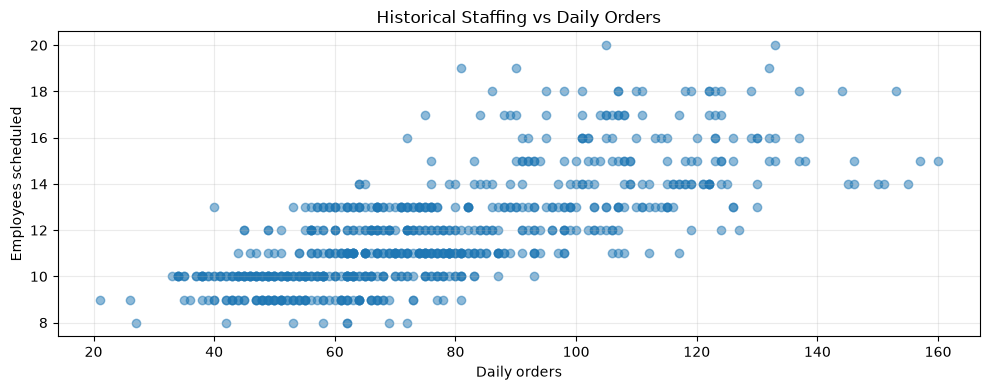

In [13]:
# ============================================================
# STAFFING RELATIONSHIP WITH DEMAND
# ============================================================

plt.figure(figsize=(10, 4))

plt.scatter(
    historical_workforce["orders"],
    historical_workforce["employees_scheduled"],
    alpha=0.5
)

plt.title("Historical Staffing vs Daily Orders")
plt.xlabel("Daily orders")
plt.ylabel("Employees scheduled")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

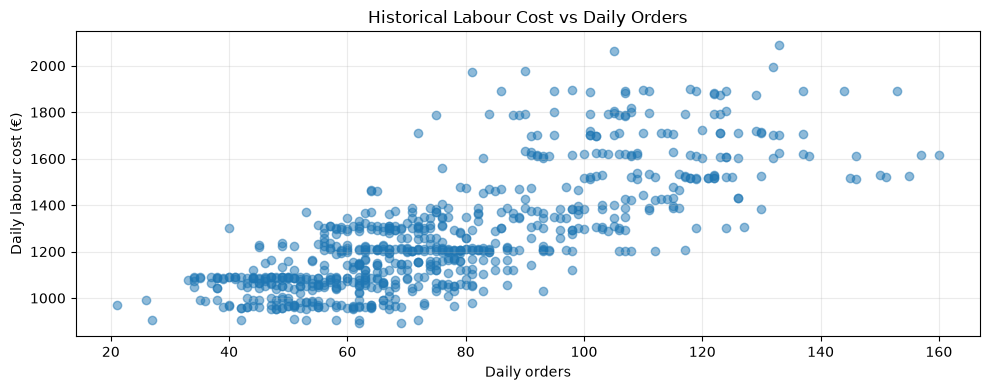

In [14]:
# ============================================================
# LABOUR COST VS DEMAND
# ============================================================

plt.figure(figsize=(10, 4))

plt.scatter(
    historical_workforce["orders"],
    historical_workforce["labour_cost"],
    alpha=0.5
)

plt.title("Historical Labour Cost vs Daily Orders")
plt.xlabel("Daily orders")
plt.ylabel("Daily labour cost (€)")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# HISTORICAL WORKFORCE KPIs
# ============================================================

total_orders = historical_workforce["orders"].sum()
total_hours = historical_workforce["total_hours"].sum()
total_labour_cost = historical_workforce["labour_cost"].sum()

avg_orders_per_day = historical_workforce["orders"].mean()
avg_staff_per_day = historical_workforce["employees_scheduled"].mean()
avg_labour_cost = historical_workforce["labour_cost"].mean()

orders_per_labour_hour = ( total_orders / total_hours if total_hours > 0 else np.nan )

labour_cost_per_order = ( total_labour_cost / total_orders if total_orders > 0 else np.nan )

workforce_kpis = pd.DataFrame({
    "KPI": [
        "Average daily orders",
        "Average employees scheduled per day",
        "Average daily labour cost",
        "Orders per labour hour",
        "Labour cost per order"
    ],
    "Value": [
        avg_orders_per_day,
        avg_staff_per_day,
        avg_labour_cost,
        orders_per_labour_hour,
        labour_cost_per_order
    ]
})

display(
    workforce_kpis.round(2)
)

,KPI,Value
0,Average daily orders,76.73
1,Average employees scheduled per day,11.90
2,Average daily labour cost,"1,263.26"
3,Orders per labour hour,1.03
4,Labour cost per order,16.46


In [16]:
# ============================================================
# DEMAND TIERS
# ============================================================

TIER_BOUNDS = [
    (60, "Low"),
    (101, "Standard"),
    (151, "High")
]


def demand_tier(orders):
    for bound, name in TIER_BOUNDS:
        if orders < bound:
            return name

    return "Very High"

historical_workforce["demand_tier"] = (
    historical_workforce["orders"]
    .apply(demand_tier)
)

display(
    historical_workforce[
        [
            "shift_date",
            "orders",
            "demand_tier",
            "employees_scheduled",
            "labour_cost"
        ]
    ].head(10)
)

,shift_date,orders,demand_tier,employees_scheduled,labour_cost
0,2024-01-01,40,Low,10,"1,092.25"
1,2024-01-02,56,Low,10,"1,048.50"
2,2024-01-03,50,Low,9,998.75
3,2024-01-04,67,Standard,13,"1,300.00"
4,2024-01-05,91,Standard,13,"1,373.75"
5,2024-01-06,103,High,13,"1,402.50"
6,2024-01-07,64,Standard,9,963.00
7,2024-01-08,34,Low,10,"1,091.25"
8,2024-01-09,55,Low,10,"1,049.00"
9,2024-01-10,47,Low,9,999.25


In [17]:
# ============================================================
# STAFFING REQUIREMENTS BY DEMAND TIER
# ============================================================

STAFFING_REQUIREMENTS = {
    "Low": [
        ("Restaurant Manager", "Full", 1),
        ("Chef", "Lunch", 1),
        ("Chef", "Dinner", 1),
        ("Kitchen Assistant", "Dinner", 1),
        ("Waiter", "Lunch", 2),
        ("Waiter", "Dinner", 2),
        ("Bartender", "Dinner", 1),
        ("Dishwasher", "Dinner", 1),
    ],

    "Standard": [
        ("Restaurant Manager", "Full", 1),
        ("Chef", "Lunch", 1),
        ("Chef", "Dinner", 2),
        ("Kitchen Assistant", "Lunch", 1),
        ("Kitchen Assistant", "Dinner", 1),
        ("Waiter", "Lunch", 2),
        ("Waiter", "Dinner", 3),
        ("Bartender", "Dinner", 1),
        ("Dishwasher", "Lunch", 1),
        ("Dishwasher", "Dinner", 1),
    ],

    "High": [
        ("Restaurant Manager", "Full", 1),
        ("Assistant Manager", "Dinner", 1),
        ("Chef", "Lunch", 1),
        ("Chef", "Dinner", 2),
        ("Kitchen Assistant", "Lunch", 1),
        ("Kitchen Assistant", "Dinner", 2),
        ("Waiter", "Lunch", 3),
        ("Waiter", "Dinner", 5),
        ("Bartender", "Dinner", 2),
        ("Dishwasher", "Lunch", 1),
        ("Dishwasher", "Dinner", 1),
    ],

    "Very High": [
        ("Restaurant Manager", "Full", 1),
        ("Assistant Manager", "Dinner", 1),
        ("Chef", "Lunch", 2),
        ("Chef", "Dinner", 2),
        ("Kitchen Assistant", "Lunch", 1),
        ("Kitchen Assistant", "Dinner", 2),
        ("Waiter", "Lunch", 4),
        ("Waiter", "Dinner", 6),
        ("Bartender", "Lunch", 1),
        ("Bartender", "Dinner", 2),
        ("Dishwasher", "Lunch", 1),
        ("Dishwasher", "Dinner", 2),
    ],
}

# ============================================================
# STAFFING REQUIREMENTS TABLE
# ============================================================

requirement_rows = []

for tier, requirements in STAFFING_REQUIREMENTS.items():
    for role, shift_type, count in requirements:
        requirement_rows.append({
            "Demand Tier": tier,
            "Role": role,
            "Shift": shift_type,
            "Required": count
        })
staffing_requirements_df = pd.DataFrame( requirement_rows )

display( staffing_requirements_df )

,Demand Tier,Role,Shift,Required
0,Low,Restaurant Manager,Full,1
1,Low,Chef,Lunch,1
2,Low,Chef,Dinner,1
3,Low,Kitchen Assistant,Dinner,1
4,Low,Waiter,Lunch,2
5,Low,Waiter,Dinner,2
6,Low,Bartender,Dinner,1
7,Low,Dishwasher,Dinner,1
8,Standard,Restaurant Manager,Full,1
9,Standard,Chef,Lunch,1


In [18]:
# ============================================================
# WORKFORCE EFFICIENCY
# ============================================================

historical_workforce["orders_per_labour_hour"] = (
    historical_workforce["orders"]
    / historical_workforce["total_hours"].replace(0, np.nan)
)

historical_workforce["labour_cost_per_order"] = (
    historical_workforce["labour_cost"]
    / historical_workforce["orders"].replace(0, np.nan)
)

display(
    historical_workforce[
        [
            "shift_date",
            "orders",
            "total_hours",
            "labour_cost",
            "orders_per_labour_hour",
            "labour_cost_per_order"
        ]
    ].head(10)
)

,shift_date,orders,total_hours,labour_cost,orders_per_labour_hour,labour_cost_per_order
0,2024-01-01,40,63.50,"1,092.25",0.63,27.31
1,2024-01-02,56,63.50,"1,048.50",0.88,18.72
2,2024-01-03,50,57.00,998.75,0.88,19.98
3,2024-01-04,67,81.00,"1,300.00",0.83,19.40
4,2024-01-05,91,81.00,"1,373.75",1.12,15.10
5,2024-01-06,103,81.00,"1,402.50",1.27,13.62
6,2024-01-07,64,57.00,963.00,1.12,15.05
7,2024-01-08,34,63.50,"1,091.25",0.54,32.10
8,2024-01-09,55,63.50,"1,049.00",0.87,19.07
9,2024-01-10,47,57.00,999.25,0.82,21.26


In [19]:
# ============================================================
# EFFICIENCY BY DEMAND TIER
# ============================================================

efficiency_by_tier = (
    historical_workforce
    .groupby("demand_tier")
    .agg(
        orders=("orders", "mean"),
        labour_hours=("total_hours", "mean"),
        labour_cost=("labour_cost", "mean"),
        orders_per_labour_hour=("orders_per_labour_hour", "mean"),
        labour_cost_per_order=("labour_cost_per_order", "mean")
    )
    .reindex(
        ["Low", "Standard", "High", "Very High"]
    )
    .reset_index()
)

display(
    efficiency_by_tier.round(2)
)

,demand_tier,orders,labour_hours,labour_cost,orders_per_labour_hour,labour_cost_per_order
0,Low,48.95,63.42,"1,073.23",0.78,22.45
1,Standard,75.61,72.88,"1,235.55",1.05,16.51
2,High,115.83,92.17,"1,591.88",1.28,13.84
3,Very High,155.20,93.30,"1,634.15",1.68,10.54


In [20]:
# ============================================================
# HISTORICAL STAFFING BY ROLE
# ============================================================

shift_role = shifts.merge(
    employees[
        [
            "employee_id",
            "role",
            "employment_type",
            "hourly_cost"
        ]
    ],
    on="employee_id",
    how="left"
)

role_shift_summary = (
    shift_role
    .groupby("role")
    .agg(
        shifts=("shift_id", "count"),
        employees=("employee_id", "nunique"),
        total_hours=("hours_worked", "sum"),
        labour_cost=("labour_cost", "sum")
    )
    .reset_index()
    .sort_values(
        "total_hours",
        ascending=False
    )
)

display(
    role_shift_summary.round(2)
)

,role,shifts,employees,total_hours,labour_cost
6,Waiter,3058,10,"18,257.00","271,568.25"
2,Chef,1798,5,"10,945.00","223,039.25"
4,Kitchen Assistant,1162,5,"7,054.00","103,787.25"
1,Bartender,880,3,"5,709.00","93,153.50"
3,Dishwasher,917,3,"5,444.50","76,110.75"
5,Restaurant Manager,495,2,"3,960.00","98,004.00"
0,Assistant Manager,386,2,"2,863.00","57,780.75"


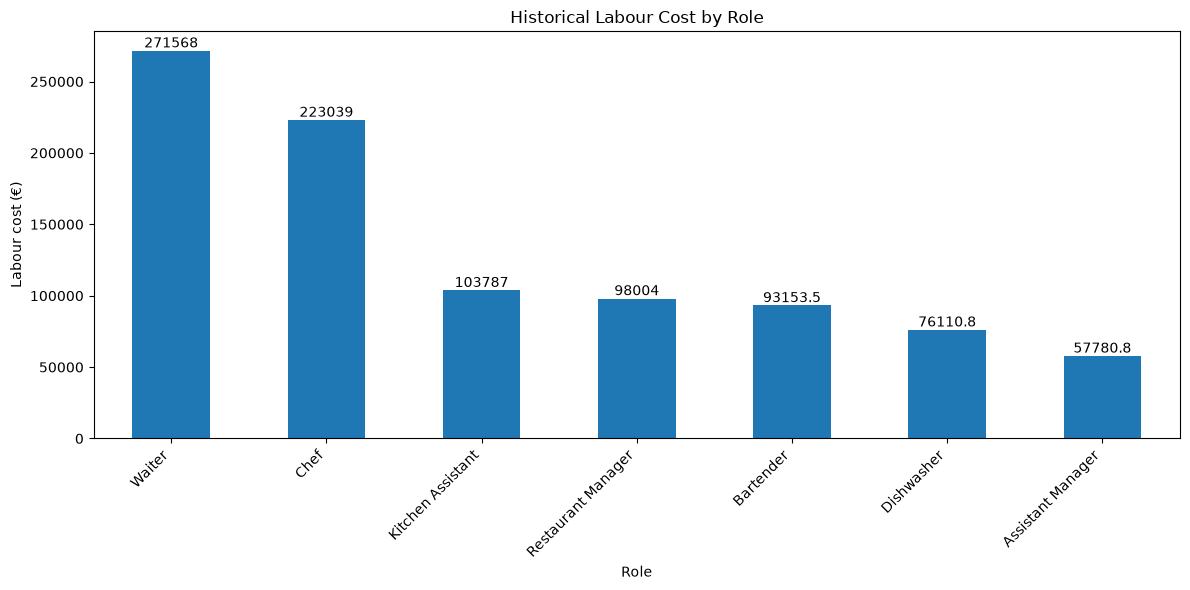

In [21]:
# ============================================================
# LABOUR COST BY ROLE
# ============================================================

plt.figure(figsize=(12, 6))

(
    role_shift_summary
    .set_index("role")["labour_cost"]
    .sort_values(ascending=False)
    .plot(kind="bar")
)

plt.title("Historical Labour Cost by Role")
plt.xlabel("Role")
plt.ylabel("Labour cost (€)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.bar_label(plt.gca().containers[0], label_type="edge")
plt.show()

In [22]:
# ============================================================
# EMPLOYEE AVAILABILITY ANALYSIS
# ============================================================

availability_summary = (
    availability
    .groupby("availability_status")
    .agg(
        employee_days=("employee_id", "count"),
        average_max_hours=("max_hours", "mean")
    )
    .reset_index()
)

display(
    availability_summary.round(2)
)

,availability_status,employee_days,average_max_hours
0,Available,147,7.06
1,Limited,9,5.50
2,Unavailable,54,0.00


In [23]:
# ============================================================
# AVAILABILITY BY ROLE
# ============================================================

availability_role = availability.merge(
    employees[
        ["employee_id", "role", "employment_type"]
    ],
    on="employee_id",
    how="left"
)

availability_by_role = (
    availability_role
    .groupby(
        ["role", "availability_status"]
    )
    .size()
    .reset_index(
        name="employee_days"
    )
)

display(
    availability_by_role
)

,role,availability_status,employee_days
0,Assistant Manager,Available,10
1,Assistant Manager,Unavailable,4
2,Bartender,Available,14
3,Bartender,Limited,1
4,Bartender,Unavailable,6
5,Chef,Available,25
6,Chef,Unavailable,10
7,Dishwasher,Available,15
8,Dishwasher,Limited,3
9,Dishwasher,Unavailable,3


In [24]:
# ============================================================
# CONTRACT HOUR LIMITS
# ============================================================

WEEKLY_HOUR_CAP = {
    "Full-time": 40.0,
    "Part-time": 30.0,
    "Minijob": 12.0
}

employees["weekly_hour_cap"] = (
    employees["employment_type"]
    .map(WEEKLY_HOUR_CAP)
)

display(
    employees[
        [
            "employee_id",
            "role",
            "employment_type",
            "hourly_cost",
            "weekly_hour_cap"
        ]
    ].head(15)
)

,employee_id,role,employment_type,hourly_cost,weekly_hour_cap
0,E001,Restaurant Manager,Full-time,25.00,40.00
1,E002,Restaurant Manager,Full-time,24.50,40.00
2,E003,Assistant Manager,Full-time,21.00,40.00
3,E004,Assistant Manager,Full-time,19.50,40.00
4,E005,Chef,Full-time,20.50,40.00
5,E006,Chef,Full-time,20.50,40.00
6,E007,Chef,Full-time,20.50,40.00
7,E008,Chef,Part-time,19.50,30.00
8,E009,Chef,Part-time,21.00,30.00
9,E010,Kitchen Assistant,Part-time,15.00,30.00


In [25]:
# ============================================================
# HISTORICAL WEEKLY HOURS
# ============================================================

shift_role["iso_year"] = (
    shift_role["shift_date"]
    .dt.isocalendar()
    .year
)

shift_role["iso_week"] = (
    shift_role["shift_date"]
    .dt.isocalendar()
    .week
)

weekly_hours = (
    shift_role
    .groupby(
        [
            "employee_id",
            "iso_year",
            "iso_week"
        ]
    )
    .agg(
        hours_worked=("hours_worked", "sum"),
        labour_cost=("labour_cost", "sum")
    )
    .reset_index()
)

weekly_hours = weekly_hours.merge(
    employees[
        [
            "employee_id",
            "employment_type",
            "weekly_hour_cap"
        ]
    ],
    on="employee_id",
    how="left"
)

weekly_hours["hours_remaining"] = (
    weekly_hours["weekly_hour_cap"]
    - weekly_hours["hours_worked"]
)

display(
    weekly_hours.head(15)
)

,employee_id,iso_year,iso_week,hours_worked,labour_cost,employment_type,weekly_hour_cap,hours_remaining
0,E001,2024,1,16.00,400.00,Full-time,40.00,24.00
1,E001,2024,2,16.00,400.00,Full-time,40.00,24.00
2,E001,2024,3,24.00,600.00,Full-time,40.00,16.00
3,E001,2024,4,16.00,400.00,Full-time,40.00,24.00
4,E001,2024,5,24.00,600.00,Full-time,40.00,16.00
5,E001,2024,6,16.00,400.00,Full-time,40.00,24.00
6,E001,2024,7,16.00,400.00,Full-time,40.00,24.00
7,E001,2024,8,24.00,600.00,Full-time,40.00,16.00
8,E001,2024,9,16.00,400.00,Full-time,40.00,24.00
9,E001,2024,10,24.00,600.00,Full-time,40.00,16.00


In [26]:
# ============================================================
# WEEKLY HOUR COMPLIANCE
# ============================================================

weekly_hours["within_contract_limit"] = (
    weekly_hours["hours_worked"]
    <= weekly_hours["weekly_hour_cap"]
)

print(
    "Weeks within contract limit:",
    weekly_hours["within_contract_limit"].mean() * 100,
    "%"
)

print(
    "Maximum weekly hours recorded:",
    weekly_hours["hours_worked"].max()
)

Weeks within contract limit: 100.0 %
Maximum weekly hours recorded: 32.5


# 4. Forecast Input

In [27]:
# ============================================================
# WORKFORCE FORECAST HORIZON
# ============================================================

FORECAST_HORIZON = 14

last_historical_date = ( daily_model["date"].max() )

forecast_dates = pd.date_range(
    start=last_historical_date + pd.Timedelta(days=1),
    periods=FORECAST_HORIZON,
    freq="D"
)

print( "Last historical date:", last_historical_date.date() )

print( "Workforce planning starts:", forecast_dates.min().date() )

print( "Workforce planning ends:", forecast_dates.max().date() )

Last historical date: 2025-12-31
Workforce planning starts: 2026-01-01
Workforce planning ends: 2026-01-14


In [28]:
# ============================================================
# REVENUE FORECAST INPUT
# ============================================================

forecast_path = "../outputs/revenue_forecast_next_14_days.csv"

revenue_forecast = pd.read_csv( forecast_path, parse_dates=["date"] )

print("Using the selected Prophet revenue forecast from Notebook 02.")

print(
    "Forecast period:",
    revenue_forecast["date"].min().date(),
    "to",
    revenue_forecast["date"].max().date()
)

print(
    "Number of forecast days:",
    len(revenue_forecast)
)

display(
    revenue_forecast.round(2)
)

Using the selected Prophet revenue forecast from Notebook 02.
Forecast period: 2026-11-03 to 2026-11-16
Number of forecast days: 14


/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_93843/200340910.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  revenue_forecast.round(2)


,date,forecast_revenue,lower_bound,upper_bound
0,2026-11-03,"2,359.81","1,789.10","2,977.77"
1,2026-11-04,"2,442.00","1,837.95","3,019.95"
2,2026-11-05,"2,916.28","2,277.98","3,480.15"
3,2026-11-06,"4,302.56","3,719.45","4,860.27"
4,2026-11-07,"4,965.01","4,317.53","5,542.98"
5,2026-11-08,"2,931.71","2,309.04","3,504.63"
6,2026-11-09,"2,035.82","1,427.17","2,632.79"
7,2026-11-10,"2,361.15","1,726.00","2,949.45"
8,2026-11-11,"2,298.62","1,743.45","2,882.38"
9,2026-11-12,"2,848.73","2,272.88","3,443.29"


In [29]:
# ============================================================
# FORECAST REVENUE → EXPECTED ORDERS
# ============================================================

historical_aov = (
    daily_model["revenue"]
    / daily_model["orders"].replace(0, np.nan)
).replace(
    [np.inf, -np.inf],
    np.nan
).median()

revenue_forecast["expected_orders"] = (
    revenue_forecast["forecast_revenue"]
    / historical_aov
).round().astype(int)

print(
    f"Historical median average order value: "
    f"€{historical_aov:.2f}"
)

display(
    revenue_forecast[
        [
            "date",
            "forecast_revenue",
            "expected_orders"
        ]
    ].round(2)
)

Historical median average order value: €36.42


/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_93843/297541434.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,date,forecast_revenue,expected_orders
0,2026-11-03,"2,359.81",65
1,2026-11-04,"2,442.00",67
2,2026-11-05,"2,916.28",80
3,2026-11-06,"4,302.56",118
4,2026-11-07,"4,965.01",136
5,2026-11-08,"2,931.71",81
6,2026-11-09,"2,035.82",56
7,2026-11-10,"2,361.15",65
8,2026-11-11,"2,298.62",63
9,2026-11-12,"2,848.73",78


In [30]:
# ============================================================
# FORECAST DEMAND FEATURES
# ============================================================

revenue_forecast["day_of_week"] = (
    revenue_forecast["date"]
    .dt.day_name()
)

revenue_forecast["is_weekend"] = (
    revenue_forecast["date"]
    .dt.dayofweek >= 5
).astype(int)

revenue_forecast["demand_tier"] = (
    revenue_forecast["expected_orders"]
    .apply(demand_tier)
)

display(
    revenue_forecast[
        [
            "date",
            "day_of_week",
            "forecast_revenue",
            "expected_orders",
            "demand_tier"
        ]
    ]
)

,date,day_of_week,forecast_revenue,expected_orders,demand_tier
0,2026-11-03,Tuesday,"2,359.81",65,Standard
1,2026-11-04,Wednesday,"2,442.00",67,Standard
2,2026-11-05,Thursday,"2,916.28",80,Standard
3,2026-11-06,Friday,"4,302.56",118,High
4,2026-11-07,Saturday,"4,965.01",136,High
5,2026-11-08,Sunday,"2,931.71",81,Standard
6,2026-11-09,Monday,"2,035.82",56,Low
7,2026-11-10,Tuesday,"2,361.15",65,Standard
8,2026-11-11,Wednesday,"2,298.62",63,Standard
9,2026-11-12,Thursday,"2,848.73",78,Standard


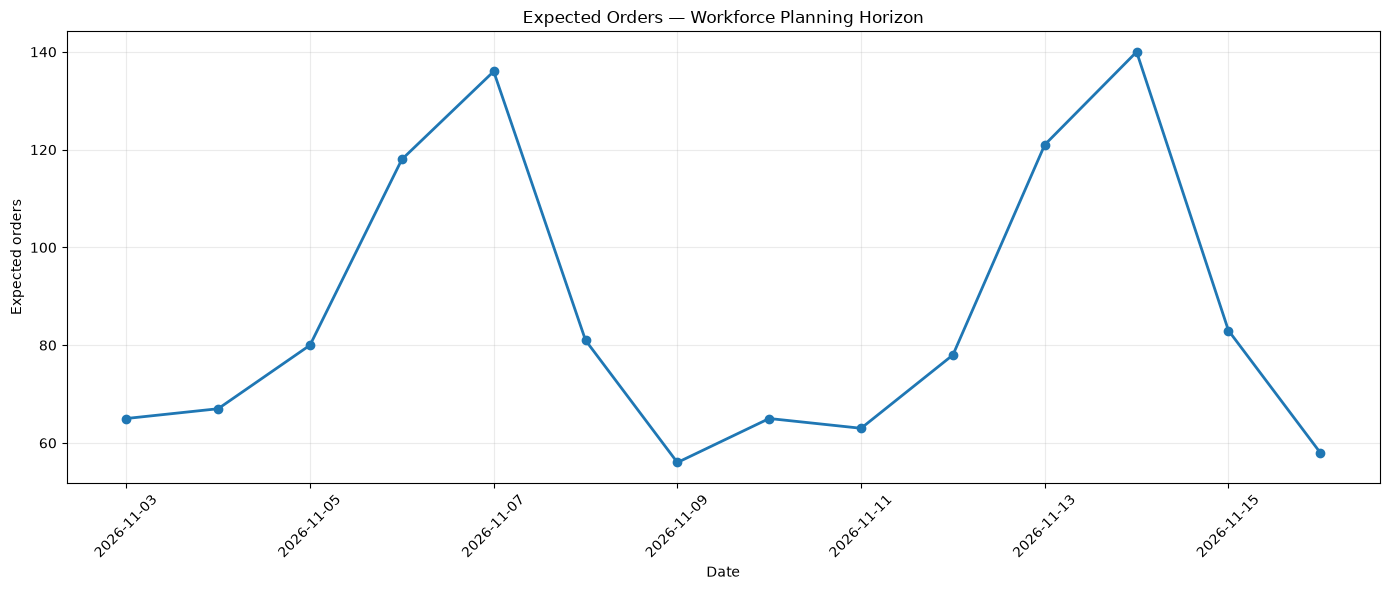

In [31]:
# ============================================================
# FORECASTED ORDERS
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    revenue_forecast["date"],
    revenue_forecast["expected_orders"],
    marker="o",
    linewidth=2
)

plt.title(
    "Expected Orders — Workforce Planning Horizon"
)

plt.xlabel("Date")
plt.ylabel("Expected orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [32]:
# ============================================================
# FORECAST STAFFING REQUIREMENTS
# ============================================================

def get_staffing_requirements(orders):

    tier = demand_tier(orders)

    rows = []

    for role, shift_type, count in STAFFING_REQUIREMENTS[tier]:

        rows.append({
            "role": role,
            "shift_type": shift_type,
            "required": count
        })

    return pd.DataFrame(rows)

# ============================================================
# BUILD FORECAST STAFFING TABLE
# ============================================================

forecast_staffing_rows = []

for _, row in revenue_forecast.iterrows():

    requirements = get_staffing_requirements(
        row["expected_orders"]
    )

    for _, requirement in requirements.iterrows():

        forecast_staffing_rows.append({
            "date": row["date"],
            "expected_orders": row["expected_orders"],
            "demand_tier": row["demand_tier"],
            "role": requirement["role"],
            "shift_type": requirement["shift_type"],
            "required": requirement["required"]
        })

forecast_staffing = pd.DataFrame(
    forecast_staffing_rows
)

display(
    forecast_staffing.head()
)

,date,expected_orders,demand_tier,role,shift_type,required
0,2026-11-03,65,Standard,Restaurant Manager,Full,1
1,2026-11-03,65,Standard,Chef,Lunch,1
2,2026-11-03,65,Standard,Chef,Dinner,2
3,2026-11-03,65,Standard,Kitchen Assistant,Lunch,1
4,2026-11-03,65,Standard,Kitchen Assistant,Dinner,1


In [33]:
# ============================================================
# DAILY STAFFING REQUIREMENT
# ============================================================

daily_required_staff = (
    forecast_staffing
    .groupby("date")
    .agg(
        expected_orders=("expected_orders", "first"),
        demand_tier=("demand_tier", "first"),
        required_staff=("required", "sum")
    )
    .reset_index()
)

display(
    daily_required_staff
)

,date,expected_orders,demand_tier,required_staff
0,2026-11-03,65,Standard,14
1,2026-11-04,67,Standard,14
2,2026-11-05,80,Standard,14
3,2026-11-06,118,High,20
4,2026-11-07,136,High,20
5,2026-11-08,81,Standard,14
6,2026-11-09,56,Low,10
7,2026-11-10,65,Standard,14
8,2026-11-11,63,Standard,14
9,2026-11-12,78,Standard,14


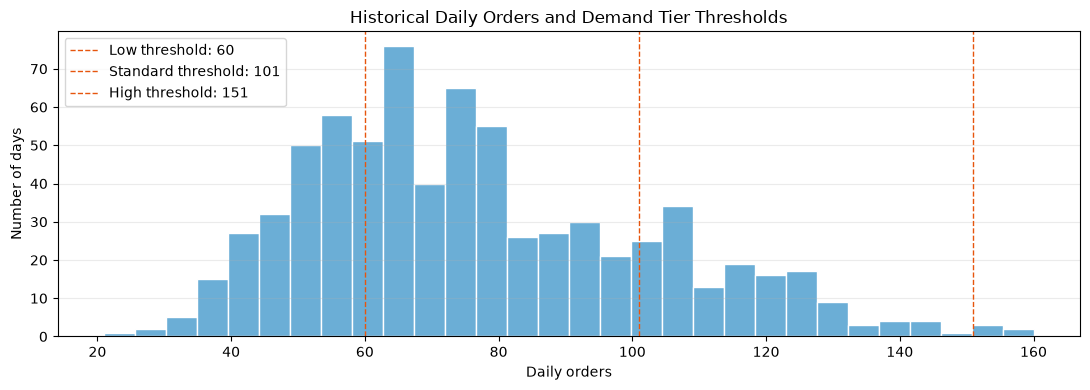

In [34]:
# ============================================================
# HISTORICAL DAILY ORDERS AND DEMAND TIERS
# ============================================================

plt.figure(figsize=(11, 4))

plt.hist(
    daily_model["orders"],
    bins=30,
    color="#6baed6",
    edgecolor="white"
)

for bound, tier_name in TIER_BOUNDS:
    plt.axvline(
        bound,
        color="#e6550d",
        linestyle="--",
        linewidth=1,
        label=f"{tier_name} threshold: {bound}"
    )

plt.title("Historical Daily Orders and Demand Tier Thresholds")
plt.xlabel("Daily orders")
plt.ylabel("Number of days")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Employee Eligibility Function
Now we move from how many people we need to which employees can actually work.

The eligibility logic respects:
- employment dates
- availability
- maximum daily hours
- weekly contractual hours
These are also the constraints used in the original dataset generation.

In [35]:
# ============================================================
# EMPLOYEE ELIGIBILITY/INELIGIBILITY CHECK
# ============================================================

SHIFT_DEFINITIONS = {
    "Lunch": {
        "start": "10:30",
        "end": "16:00",
        "hours": 5.5
    },

    "Dinner": {
        "start": "16:30",
        "end": "23:00",
        "hours": 6.5
    },

    "Full": {
        "start": "11:30",
        "end": "20:00",
        "hours": 8.0
    }
}


def employee_ineligibility_reason(
    employee,
    availability_row,
    date,
    shift_hours,
    weekly_hours_used
):

    # Employment dates
    if date < employee["employment_start"]:
        return "not employed yet"

    if (
        pd.notna(employee["employment_end"])
        and date > employee["employment_end"]
    ):
        return "employment ended"

    # Availability
    if availability_row is None:
        return "availability record missing"
    
    if availability_row.availability_status== "Unavailable":
        return "unavailable that weekday"

    # Daily availability
    if availability_row.max_hours < shift_hours:
        return "insufficient daily hours"


    # Weekly contract limit
    iso = date.isocalendar()
    if (
        weekly_hours_used
        + shift_hours
        > employee["weekly_hour_cap"]
    ):
        return "weekly hour cap reached"

    return None

Build Forecast Roster

In [36]:
# ============================================================
# BUILD FORECAST ROSTER AND EXPLAIN GAPS
# ============================================================

def build_forecast_roster(
    forecast_staffing,
    employees,
    availability
):
    employees_local = employees.copy()
    availability_local = availability.copy()

    employees_local["weekly_hour_cap"] = (
        employees_local["employment_type"]
        .map(WEEKLY_HOUR_CAP)
    )

    # Availability uses Monday=1 through Sunday=7.
    availability_lookup = {
        (row.employee_id, int(row.day_of_week_num)): row
        for row in availability_local.itertuples(index=False)
    }

    weekly_hours_used = defaultdict(float)
    roster_rows = []
    gap_rows = []

    for _, requirement in forecast_staffing.iterrows():
        date = pd.Timestamp(requirement["date"])
        role = requirement["role"]
        shift_type = requirement["shift_type"]
        required_count = int(requirement["required"])

        shift_info = SHIFT_DEFINITIONS[shift_type]
        shift_hours = shift_info["hours"]

        # Python weekday is Monday=0; availability table is Monday=1.
        availability_day = date.dayofweek + 1
        iso = date.isocalendar()

        candidates = []
        reason_counts = {}

        role_employees = employees_local[
            employees_local["role"] == role
        ]

        for _, employee in role_employees.iterrows():
            availability_row = availability_lookup.get(
                (employee["employee_id"], availability_day)
            )

            week_key = (
                employee["employee_id"],
                int(iso.year),
                int(iso.week)
            )

            reason = employee_ineligibility_reason(
                employee,
                availability_row,
                date,
                shift_hours,
                weekly_hours_used[week_key]
            )

            if reason is None:
                candidates.append(
                    (employee, weekly_hours_used[week_key])
                )
            else:
                reason_counts[reason] = (
                    reason_counts.get(reason, 0) + 1
                )

        # Keep the existing selection rule:
        # prioritize employees with the fewest assigned hours.
        candidates.sort(key=lambda item: item[1])
        selected = candidates[:required_count]

        for employee, _ in selected:
            week_key = (
                employee["employee_id"],
                int(iso.year),
                int(iso.week)
            )

            weekly_hours_used[week_key] += shift_hours
            labour_cost = shift_hours * employee["hourly_cost"]

            roster_rows.append({
                "date": date,
                "role": role,
                "shift_type": shift_type,
                "employee_id": employee["employee_id"],
                "employee_name": employee["employee_name"],
                "employment_type": employee["employment_type"],
                "start_time": shift_info["start"],
                "end_time": shift_info["end"],
                "hours": shift_hours,
                "hourly_cost": employee["hourly_cost"],
                "labour_cost": labour_cost
            })

        unfilled_count = required_count - len(selected)

        if unfilled_count > 0:
            reason_parts = []

            if not role_employees.empty and candidates:
                reason_parts.append(
                    f"only {len(candidates)} eligible employee(s) "
                    f"for {required_count} required position(s)"
                )
            elif role_employees.empty:
                reason_parts.append("no employees with this role")

            reason_parts.extend(
                f"{reason} ({count} employee(s))"
                for reason, count in reason_counts.items()
            )

            gap_rows.append({
                "date": date,
                "weekday": date.day_name(),
                "role": role,
                "shift_type": shift_type,
                "hours": shift_hours,
                "required": required_count,
                "assigned": len(selected),
                "unfilled": unfilled_count,
                "reason": "; ".join(reason_parts)
            })

    recommended_roster = pd.DataFrame(roster_rows)
    staffing_gaps = pd.DataFrame(gap_rows)

    return recommended_roster, staffing_gaps

In [37]:
# ============================================================
# GENERATE RECOMMENDED ROSTER AND STAFFING GAPS
# ============================================================

recommended_roster, staffing_gaps = build_forecast_roster(
    forecast_staffing,
    employees,
    availability
)
print( "Recommended roster positions:", len(recommended_roster) )
print( "Unfilled staffing requirements:", len(staffing_gaps) )



Recommended roster positions: 200
Unfilled staffing requirements: 10


In [38]:
# ============================================================
# UNCOVERED POSITIONS AND REASONS
# ============================================================

if staffing_gaps.empty:
    print("All required staffing positions are covered.")
else:
    display(
        staffing_gaps[
            [
                "date",
                "weekday",
                "role",
                "shift_type",
                "hours",
                "required",
                "assigned",
                "unfilled",
                "reason"
            ]
        ].sort_values(
            ["date", "role", "shift_type"]
        ).reset_index(drop=True)
    )

,date,weekday,role,shift_type,hours,required,assigned,unfilled,reason
0,2026-11-06,Friday,Kitchen Assistant,Dinner,6.50,2,1,1,only 1 eligible employee(s) for 2 required pos...
1,2026-11-07,Saturday,Dishwasher,Dinner,6.50,1,0,1,weekly hour cap reached (1 employee(s)); insuf...
2,2026-11-08,Sunday,Dishwasher,Dinner,6.50,1,0,1,weekly hour cap reached (2 employee(s)); emplo...
3,2026-11-08,Sunday,Dishwasher,Lunch,5.50,1,0,1,weekly hour cap reached (2 employee(s)); emplo...
4,2026-11-12,Thursday,Dishwasher,Dinner,6.50,1,0,1,unavailable that weekday (1 employee(s)); week...
5,2026-11-13,Friday,Kitchen Assistant,Dinner,6.50,2,1,1,only 1 eligible employee(s) for 2 required pos...
6,2026-11-14,Saturday,Dishwasher,Dinner,6.50,1,0,1,weekly hour cap reached (1 employee(s)); insuf...
7,2026-11-14,Saturday,Waiter,Dinner,6.50,5,3,2,only 3 eligible employee(s) for 5 required pos...
8,2026-11-15,Sunday,Dishwasher,Dinner,6.50,1,0,1,weekly hour cap reached (2 employee(s)); emplo...
9,2026-11-15,Sunday,Waiter,Dinner,6.50,3,1,2,only 1 eligible employee(s) for 3 required pos...


Check Whether Requirements Were Fully Covered.

A staffing recommendation is not useful if we simply assume every required employee is available.

In [39]:
# ============================================================
# STAFFING COVERAGE CHECK
# ============================================================

assigned_staffing = (recommended_roster.groupby(["date", "role", "shift_type"])
    .size()
    .reset_index(
        name="assigned"
    )
)

staffing_coverage = forecast_staffing.merge(
    assigned_staffing,
    on=[
        "date",
        "role",
        "shift_type"
    ],
    how="left"
)

staffing_coverage["assigned"] = (
    staffing_coverage["assigned"]
    .fillna(0)
)

staffing_coverage["shortfall"] = (
    staffing_coverage["required"]
    - staffing_coverage["assigned"]
)

staffing_coverage["coverage_status"] = np.where(
    staffing_coverage["shortfall"] > 0,
    "Under-covered",
    "Covered"
)

display(
    staffing_coverage
)

,date,expected_orders,demand_tier,role,shift_type,required,assigned,shortfall,coverage_status
0,2026-11-03,65,Standard,Restaurant Manager,Full,1,1.00,0.00,Covered
1,2026-11-03,65,Standard,Chef,Lunch,1,1.00,0.00,Covered
2,2026-11-03,65,Standard,Chef,Dinner,2,2.00,0.00,Covered
3,2026-11-03,65,Standard,Kitchen Assistant,Lunch,1,1.00,0.00,Covered
4,2026-11-03,65,Standard,Kitchen Assistant,Dinner,1,1.00,0.00,Covered
...,...,...,...,...,...,...,...,...,...
135,2026-11-16,58,Low,Kitchen Assistant,Dinner,1,1.00,0.00,Covered
136,2026-11-16,58,Low,Waiter,Lunch,2,2.00,0.00,Covered
137,2026-11-16,58,Low,Waiter,Dinner,2,2.00,0.00,Covered
138,2026-11-16,58,Low,Bartender,Dinner,1,1.00,0.00,Covered


In [40]:
# ============================================================
# STAFFING COVERAGE SUMMARY
# ============================================================

coverage_summary = (
    staffing_coverage
    .groupby("coverage_status")
    .size()
    .reset_index(
        name="requirements"
    )
)

display(
    coverage_summary
)

,coverage_status,requirements
0,Covered,130
1,Under-covered,10


In [41]:
# ============================================================
# FORECAST LABOUR COST
# ============================================================

daily_forecast_labour = (
    recommended_roster
    .groupby("date")
    .agg(
        scheduled_employees=(
            "employee_id",
            "nunique"
        ),
        labour_hours=(
            "hours",
            "sum"
        ),
        labour_cost=(
            "labour_cost",
            "sum"
        )
    )
    .reset_index()
)

display(
    daily_forecast_labour.round(2)
)

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_93843/3021050035.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  daily_forecast_labour.round(2)


,date,scheduled_employees,labour_hours,labour_cost
0,2026-11-03,13,87.50,"1,483.75"
1,2026-11-04,11,87.50,"1,461.00"
2,2026-11-05,10,87.50,"1,497.50"
3,2026-11-06,15,119.00,"1,989.75"
4,2026-11-07,17,119.00,"2,002.75"
5,2026-11-08,10,75.50,"1,311.25"
6,2026-11-09,9,63.50,"1,097.25"
7,2026-11-10,11,87.50,"1,474.50"
8,2026-11-11,10,87.50,"1,470.75"
9,2026-11-12,10,81.00,"1,407.00"


Combine Revenue, Orders, Staffing and Cost

In [42]:
# ============================================================
# FINAL WORKFORCE FORECAST TABLE
# ============================================================

workforce_forecast = (
    daily_required_staff
    .merge(
        daily_forecast_labour,
        on="date",
        how="left"
    )
)

workforce_forecast["labour_cost"] = (
    workforce_forecast["labour_cost"]
    .fillna(0)
)

workforce_forecast["labour_hours"] = (
    workforce_forecast["labour_hours"]
    .fillna(0)
)

workforce_forecast["scheduled_employees"] = (
    workforce_forecast[
        "scheduled_employees"
    ]
    .fillna(0)
)

workforce_forecast = workforce_forecast.merge(
    revenue_forecast[
        [
            "date",
            "forecast_revenue"
        ]
    ],
    on="date",
    how="left"
)

workforce_forecast[
    "labour_cost_pct_revenue"
] = (
    workforce_forecast["labour_cost"]
    / workforce_forecast["forecast_revenue"]
    * 100
)

workforce_forecast[
    "forecast_orders_per_labour_hour"
] = (
    workforce_forecast["expected_orders"]
    / workforce_forecast["labour_hours"]
    .replace(0, np.nan)
)

display(
    workforce_forecast.round(2)
)

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_93843/1382597557.py:59: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  workforce_forecast.round(2)


,date,expected_orders,demand_tier,required_staff,scheduled_employees,labour_hours,labour_cost,forecast_revenue,labour_cost_pct_revenue,forecast_orders_per_labour_hour
0,2026-11-03,65,Standard,14,13,87.50,"1,483.75","2,359.81",62.88,0.74
1,2026-11-04,67,Standard,14,11,87.50,"1,461.00","2,442.00",59.83,0.77
2,2026-11-05,80,Standard,14,10,87.50,"1,497.50","2,916.28",51.35,0.91
3,2026-11-06,118,High,20,15,119.00,"1,989.75","4,302.56",46.25,0.99
4,2026-11-07,136,High,20,17,119.00,"2,002.75","4,965.01",40.34,1.14
5,2026-11-08,81,Standard,14,10,75.50,"1,311.25","2,931.71",44.73,1.07
6,2026-11-09,56,Low,10,9,63.50,"1,097.25","2,035.82",53.90,0.88
7,2026-11-10,65,Standard,14,11,87.50,"1,474.50","2,361.15",62.45,0.74
8,2026-11-11,63,Standard,14,10,87.50,"1,470.75","2,298.62",63.98,0.72
9,2026-11-12,78,Standard,14,10,81.00,"1,407.00","2,848.73",49.39,0.96


In [43]:
# ============================================================
# FORECAST WORKFORCE KPIs
# ============================================================

forecast_total_revenue = (
    workforce_forecast[
        "forecast_revenue"
    ].sum()
)

forecast_total_orders = (
    workforce_forecast[
        "expected_orders"
    ].sum()
)

forecast_labour_cost = (
    workforce_forecast[
        "labour_cost"
    ].sum()
)

forecast_labour_hours = (
    workforce_forecast[
        "labour_hours"
    ].sum()
)

forecast_labour_cost_pct = (
    forecast_labour_cost
    / forecast_total_revenue
    * 100
)

forecast_orders_per_labour_hour = (
    forecast_total_orders
    / forecast_labour_hours
)

forecast_labour_cost_per_order = (
    forecast_labour_cost
    / forecast_total_orders
)

forecast_kpis = pd.DataFrame({
    "KPI": [
        "Forecast revenue",
        "Expected orders",
        "Labour hours",
        "Labour cost",
        "Labour cost as % of revenue",
        "Orders per labour hour",
        "Labour cost per order"
    ],
    "Value": [
        forecast_total_revenue,
        forecast_total_orders,
        forecast_labour_hours,
        forecast_labour_cost,
        forecast_labour_cost_pct,
        forecast_orders_per_labour_hour,
        forecast_labour_cost_per_order
    ]
})

display(
    forecast_kpis.round(2)
)

,KPI,Value
0,Forecast revenue,"44,111.13"
1,Expected orders,"1,211.00"
2,Labour hours,"1,252.00"
3,Labour cost,"21,295.00"
4,Labour cost as % of revenue,48.28
5,Orders per labour hour,0.97
6,Labour cost per order,17.58


In [44]:
# ============================================================
# RECOMMENDED STAFF BY ROLE
# ============================================================

recommended_by_role = (
    recommended_roster
    .groupby("role")
    .agg(
        employees=(
            "employee_id",
            "nunique"
        ),
        shifts=(
            "employee_id",
            "count"
        ),
        hours=(
            "hours",
            "sum"
        ),
        labour_cost=(
            "labour_cost",
            "sum"
        )
    )
    .reset_index()
    .sort_values(
        "hours",
        ascending=False
    )
)

display(
    recommended_by_role.round(2)
)

,role,employees,shifts,hours,labour_cost
6,Waiter,9,76,462.00,"6,866.50"
2,Chef,4,40,246.00,"5,065.25"
4,Kitchen Assistant,4,28,170.00,"2,487.75"
3,Dishwasher,2,20,119.00,"1,666.00"
1,Bartender,3,18,117.00,"1,911.00"
5,Restaurant Manager,2,14,112.00,"2,772.00"
0,Assistant Manager,2,4,26.00,526.50


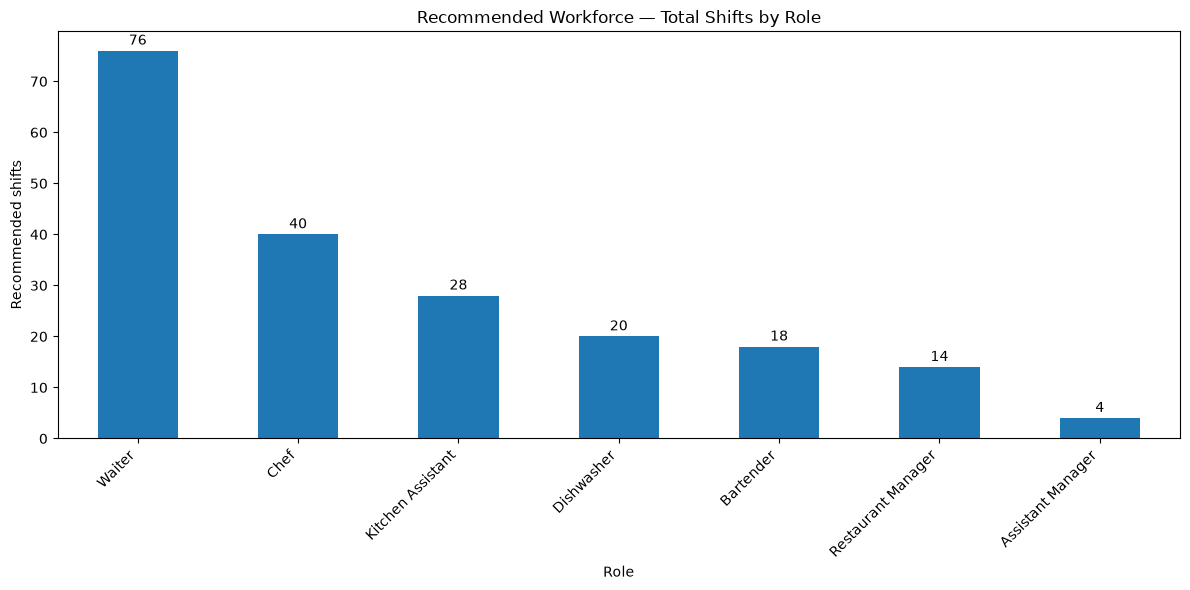

In [45]:
# ============================================================
# Chart: RECOMMENDED STAFFING BY ROLE
# ============================================================

plt.figure(figsize=(12, 6))

bar=(
    recommended_by_role
    .set_index("role")["shifts"]
    .sort_values(ascending=False)
    .plot(kind="bar")
)

plt.title( "Recommended Workforce — Total Shifts by Role" )
bar.bar_label(bar.containers[0], padding=2)
plt.xlabel("Role")
plt.ylabel("Recommended shifts")

plt.xticks( rotation=45, ha="right" )

plt.tight_layout()
plt.show()

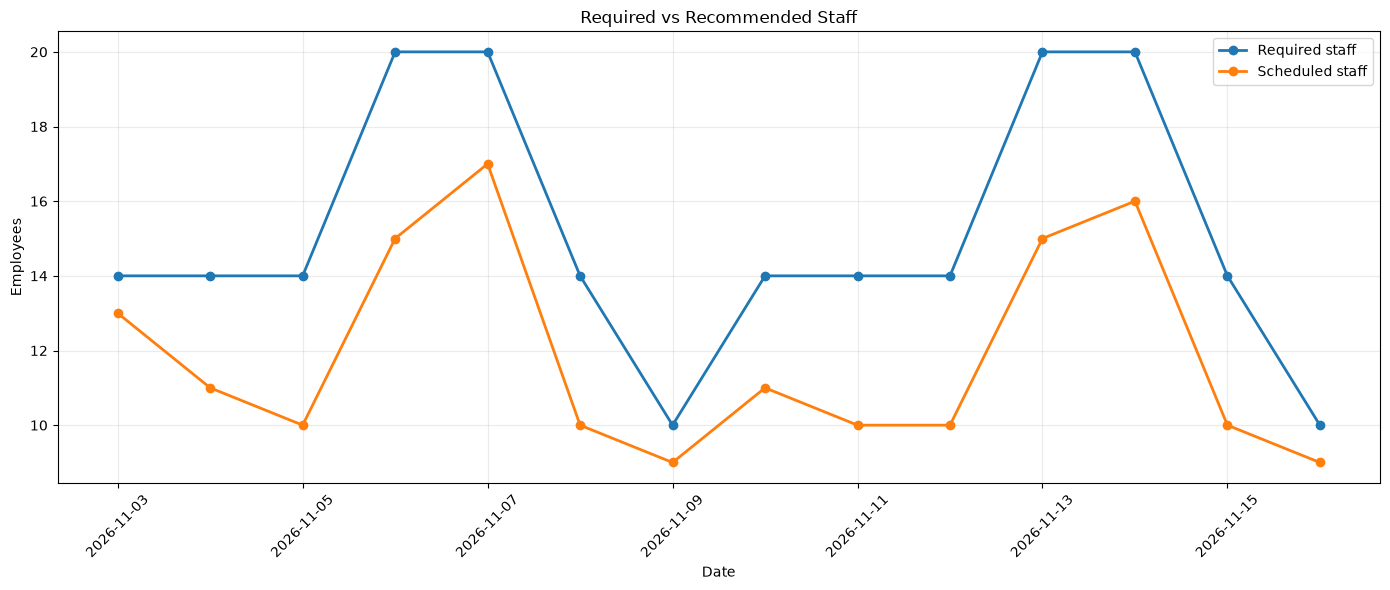

In [46]:
# ============================================================
# DAILY STAFFING REQUIREMENT
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    workforce_forecast["date"],
    workforce_forecast["required_staff"],
    marker="o",
    linewidth=2,
    label="Required staff"
)

plt.plot(
    workforce_forecast["date"],
    workforce_forecast["scheduled_employees"],
    marker="o",
    linewidth=2,
    label="Scheduled staff"
)

plt.title(
    "Required vs Recommended Staff"
)

plt.xlabel("Date")
plt.ylabel("Employees")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

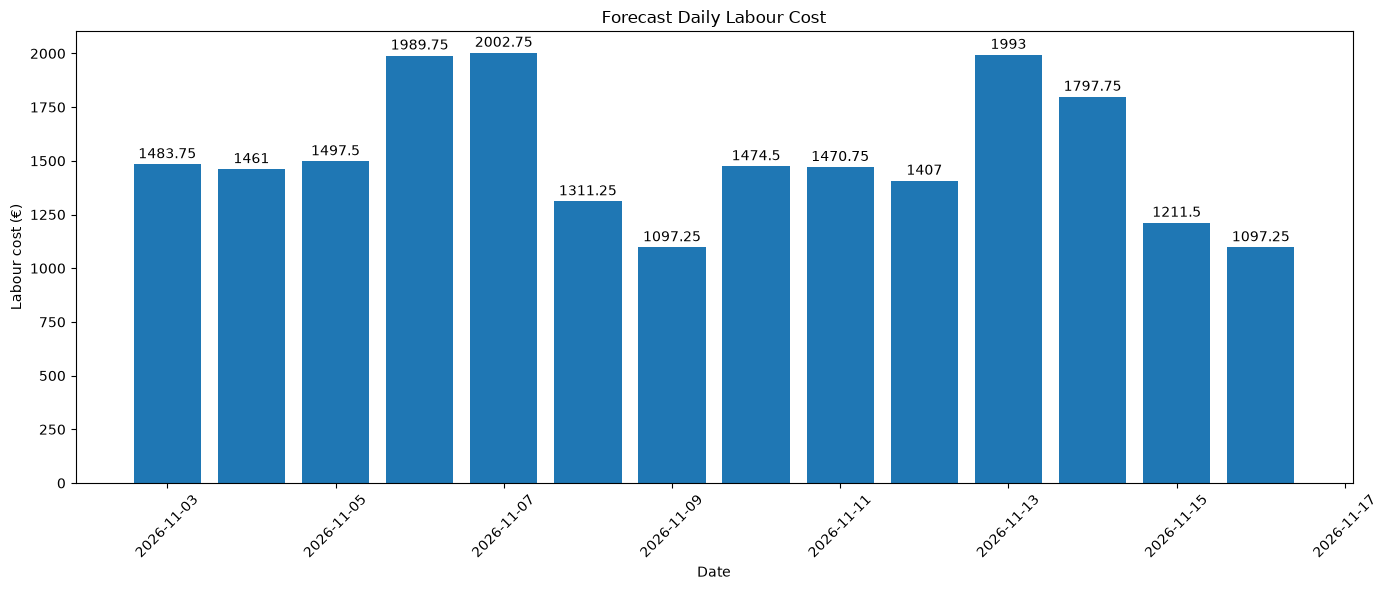

In [47]:
# ============================================================
# DAILY FORECAST LABOUR COST
# ============================================================

plt.figure(figsize=(14, 6))

plt.bar(
    workforce_forecast["date"],
    workforce_forecast["labour_cost"]
)

plt.title(
    "Forecast Daily Labour Cost"
)
plt.bar_label(plt.gca().containers[0], label_type="edge", padding=2)
plt.xlabel("Date")
plt.ylabel("Labour cost (€)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

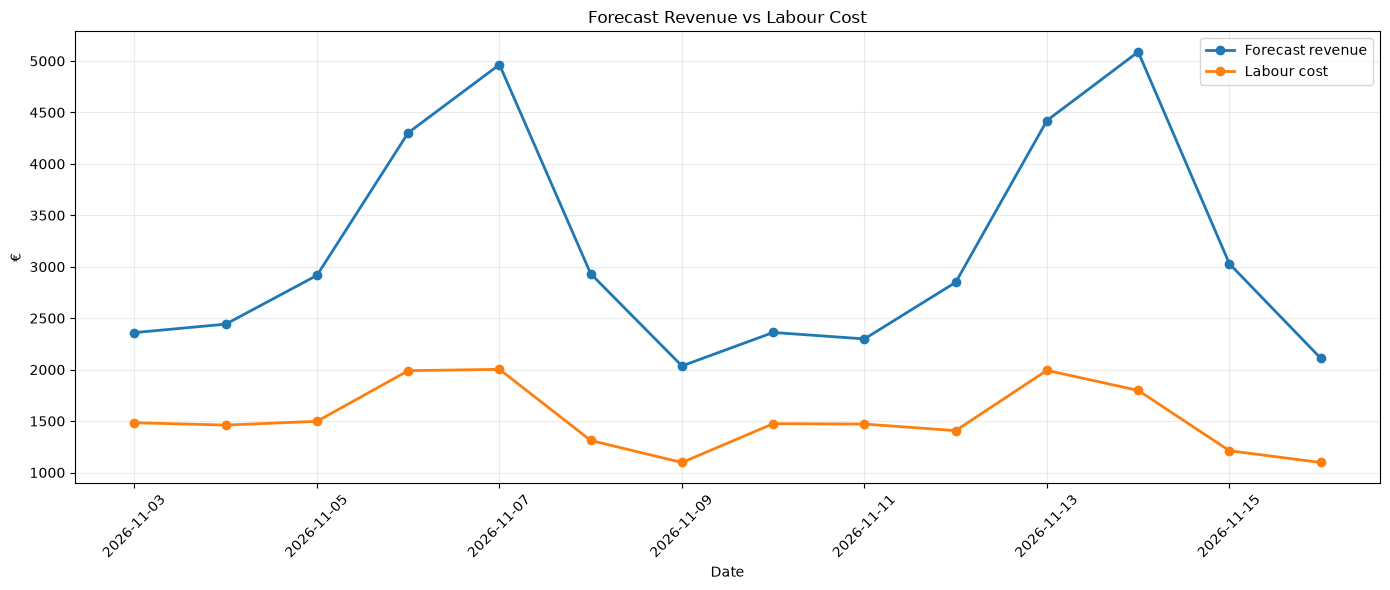

In [48]:
# ============================================================
# LABOUR COST VS FORECAST REVENUE
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    workforce_forecast["date"],
    workforce_forecast["forecast_revenue"],
    marker="o",
    linewidth=2,
    label="Forecast revenue"
)

plt.plot(
    workforce_forecast["date"],
    workforce_forecast["labour_cost"],
    marker="o",
    linewidth=2,
    label="Labour cost"
)

plt.title(
    "Forecast Revenue vs Labour Cost"
)

plt.xlabel("Date")
plt.ylabel("€")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [49]:
# ============================================================
# UNDER-COVERED SHIFTS
# ============================================================

under_covered = (
    staffing_coverage[
        staffing_coverage["shortfall"] > 0
    ]
    .sort_values(
        ["date", "shortfall"],
        ascending=[True, False]
    )
)

display(
    under_covered
)

,date,expected_orders,demand_tier,role,shift_type,required,assigned,shortfall,coverage_status
35,2026-11-06,118,High,Kitchen Assistant,Dinner,2,1.00,1.00,Under-covered
51,2026-11-07,136,High,Dishwasher,Dinner,1,0.00,1.00,Under-covered
60,2026-11-08,81,Standard,Dishwasher,Lunch,1,0.00,1.00,Under-covered
61,2026-11-08,81,Standard,Dishwasher,Dinner,1,0.00,1.00,Under-covered
99,2026-11-12,78,Standard,Dishwasher,Dinner,1,0.00,1.00,Under-covered
105,2026-11-13,121,High,Kitchen Assistant,Dinner,2,1.00,1.00,Under-covered
118,2026-11-14,140,High,Waiter,Dinner,5,3.00,2.00,Under-covered
121,2026-11-14,140,High,Dishwasher,Dinner,1,0.00,1.00,Under-covered
128,2026-11-15,83,Standard,Waiter,Dinner,3,1.00,2.00,Under-covered
131,2026-11-15,83,Standard,Dishwasher,Dinner,1,0.00,1.00,Under-covered


In [50]:
# ============================================================
# HIGHEST LABOUR-COST DAYS
# ============================================================

highest_cost_days = (
    workforce_forecast[
        [
            "date",
            "expected_orders",
            "demand_tier",
            "scheduled_employees",
            "labour_hours",
            "labour_cost",
            "labour_cost_pct_revenue"
        ]
    ]
    .sort_values(
        "labour_cost",
        ascending=False
    )
)

display(
    highest_cost_days.head(10).round(2)
)

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_93843/3343181838.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  highest_cost_days.head(10).round(2)


,date,expected_orders,demand_tier,scheduled_employees,labour_hours,labour_cost,labour_cost_pct_revenue
4,2026-11-07,136,High,17,119.00,"2,002.75",40.34
10,2026-11-13,121,High,15,119.00,"1,993.00",45.08
3,2026-11-06,118,High,15,119.00,"1,989.75",46.25
11,2026-11-14,140,High,16,106.00,"1,797.75",35.33
2,2026-11-05,80,Standard,10,87.50,"1,497.50",51.35
0,2026-11-03,65,Standard,13,87.50,"1,483.75",62.88
7,2026-11-10,65,Standard,11,87.50,"1,474.50",62.45
8,2026-11-11,63,Standard,10,87.50,"1,470.75",63.98
1,2026-11-04,67,Standard,11,87.50,"1,461.00",59.83
9,2026-11-12,78,Standard,10,81.00,"1,407.00",49.39


In [51]:
# ============================================================
# RECOMMENDED EMPLOYEE WORKLOAD
# ============================================================

employee_workload = (
    recommended_roster
    .groupby(
        [
            "employee_id",
            "employee_name",
            "role",
            "employment_type"
        ]
    )
    .agg(
        shifts=("date", "count"),
        total_hours=("hours", "sum"),
        labour_cost=("labour_cost", "sum")
    )
    .reset_index()
)

employee_workload = employee_workload.merge(
    employees[
        [
            "employee_id",
            "weekly_hour_cap"
        ]
    ],
    on="employee_id",
    how="left"
)

display(
    employee_workload
    .sort_values(
        "total_hours",
        ascending=False
    )
    .round(2)
)

,employee_id,employee_name,role,employment_type,shifts,total_hours,labour_cost,weekly_hour_cap
13,E016,Laura Jung,Waiter,Full-time,13,79.50,"1,192.50",40.00
14,E017,Tom Richter,Waiter,Full-time,13,75.50,"1,170.25",40.00
6,E007,Felix Nowak,Chef,Full-time,12,74.00,"1,517.00",40.00
12,E015,Carla Weber,Waiter,Full-time,12,72.00,"1,116.00",40.00
5,E006,Anna Wagner,Chef,Full-time,11,67.50,"1,383.75",40.00
25,E029,Felix Schulz,Dishwasher,Part-time,10,61.00,854.00,30.00
4,E005,Katarina Fischer,Chef,Full-time,10,60.00,"1,230.00",40.00
24,E028,Nina Schmidt,Dishwasher,Part-time,10,58.00,812.00,30.00
17,E021,Piotr Huber,Waiter,Part-time,9,56.50,819.25,30.00
16,E019,Laura Meyer,Waiter,Part-time,9,56.50,847.50,30.00


In [52]:
# ============================================================
# FORECAST WEEKLY HOURS CHECK
# ============================================================

recommended_roster["iso_year"] = (
    recommended_roster["date"]
    .dt.isocalendar()
    .year
)

recommended_roster["iso_week"] = (
    recommended_roster["date"]
    .dt.isocalendar()
    .week
)

forecast_weekly_hours = (
    recommended_roster
    .groupby(
        [
            "employee_id",
            "employee_name",
            "employment_type",
            "iso_year",
            "iso_week"
        ]
    )
    .agg(
        hours=("hours", "sum")
    )
    .reset_index()
)

forecast_weekly_hours["weekly_cap"] = (
    forecast_weekly_hours["employment_type"]
    .map(WEEKLY_HOUR_CAP)
)

forecast_weekly_hours["within_limit"] = (
    forecast_weekly_hours["hours"]
    <= forecast_weekly_hours["weekly_cap"]
)

display(
    forecast_weekly_hours.round(2)
)

,employee_id,employee_name,employment_type,iso_year,iso_week,hours,weekly_cap,within_limit
0,E001,Clara Krause,Full-time,2026,45,24.00,40.00,True
1,E001,Clara Krause,Full-time,2026,46,32.00,40.00,True
2,E002,Piotr Lange,Full-time,2026,45,24.00,40.00,True
3,E002,Piotr Lange,Full-time,2026,46,24.00,40.00,True
4,E002,Piotr Lange,Full-time,2026,47,8.00,40.00,True
...,...,...,...,...,...,...,...,...
56,E028,Nina Schmidt,Part-time,2026,45,28.50,30.00,True
57,E028,Nina Schmidt,Part-time,2026,46,29.50,30.00,True
58,E029,Felix Schulz,Part-time,2026,45,25.00,30.00,True
59,E029,Felix Schulz,Part-time,2026,46,29.50,30.00,True


In [53]:
# ============================================================
# FINAL WORKFORCE CONSTRAINT CHECK
# ============================================================

checks = {
    "No negative labour costs":
        (recommended_roster["labour_cost"] >= 0).all(),

    "All scheduled employees exist":
        recommended_roster["employee_id"]
        .isin(employees["employee_id"])
        .all(),

    "Weekly hours within contract limits":
        forecast_weekly_hours["within_limit"].all(),

    "No employee scheduled twice in same shift":
        ~recommended_roster.duplicated(
            [
                "date",
                "employee_id",
                "shift_type"
            ]
        ).any()
}

constraint_results = pd.DataFrame({
    "Check": list(checks.keys()),
    "Passed": list(checks.values())
})

display(
    constraint_results
)

,Check,Passed
0,No negative labour costs,True
1,All scheduled employees exist,True
2,Weekly hours within contract limits,True
3,No employee scheduled twice in same shift,True


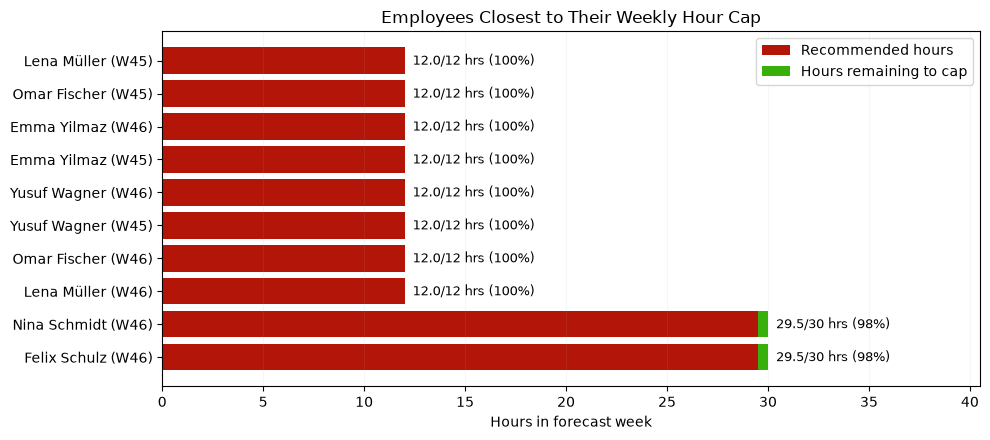

In [54]:
# ============================================================
# EMPLOYEE HOURS VS WEEKLY CONTRACT CAP
# ============================================================

roster_hours = recommended_roster.copy()

roster_hours["iso_year"] = (
    roster_hours["date"].dt.isocalendar().year.astype(int)
)

roster_hours["iso_week"] = (
    roster_hours["date"].dt.isocalendar().week.astype(int)
)

employee_weekly_hours = (
    roster_hours
    .groupby(
        [
            "employee_id",
            "employee_name",
            "employment_type",
            "iso_year",
            "iso_week"
        ],
        as_index=False
    )
    .agg(hours=("hours", "sum"))
)

employee_weekly_hours["weekly_cap"] = (
    employee_weekly_hours["employment_type"]
    .map(WEEKLY_HOUR_CAP)
)

employee_weekly_hours["hours_remaining"] = (
    employee_weekly_hours["weekly_cap"]
    - employee_weekly_hours["hours"]
)

employee_weekly_hours["cap_used_pct"] = (
    employee_weekly_hours["hours"]
    / employee_weekly_hours["weekly_cap"]
    * 100
)

# Show the 10 employee-weeks closest to their weekly cap
closest_to_cap = (
    employee_weekly_hours
    .sort_values("cap_used_pct", ascending=False)
    .head(10)
    .sort_values("cap_used_pct")
    .copy()
)

if closest_to_cap.empty:
    print("No roster assignments available to chart.")
else:
    closest_to_cap["employee_week"] = (
        closest_to_cap["employee_name"]
        + " (W"
        + closest_to_cap["iso_week"].astype(str)
        + ")"
    )

    fig, ax = plt.subplots(
        figsize=(10, max(4, len(closest_to_cap) * 0.45))
    )

    ax.barh(
        closest_to_cap["employee_week"],
        closest_to_cap["hours"],
        label="Recommended hours",
        color="#B31608"
    )

    ax.barh(
        closest_to_cap["employee_week"],
        closest_to_cap["hours_remaining"],
        left=closest_to_cap["hours"],
        label="Hours remaining to cap",
        color="#37b00b"
    )

    for y, (_, row) in enumerate(closest_to_cap.iterrows()):
        ax.text(
            row["weekly_cap"] + 0.4,
            y,
            f'{row["hours"]:.1f}/{row["weekly_cap"]:.0f} hrs '
            f'({row["cap_used_pct"]:.0f}%)',
            va="center",
            fontsize=9
        )

    ax.set_title("Employees Closest to Their Weekly Hour Cap")
    ax.set_xlabel("Hours in forecast week")
    ax.set_ylabel("")
    ax.set_xlim(
        0,
        closest_to_cap["weekly_cap"].max() * 1.35
    )
    ax.legend(loc="upper right")
    ax.grid(axis="x", alpha=0.1)

    plt.tight_layout()
    plt.show()

In [55]:
# ============================================================
# FINAL WORKFORCE INTELLIGENCE SUMMARY
# ============================================================

print("=" * 65)
print("RESTRODINE — WORKFORCE INTELLIGENCE")
print("=" * 65)

print(
    f"\nPlanning horizon: "
    f"{workforce_forecast['date'].min().date()} "
    f"→ "
    f"{workforce_forecast['date'].max().date()}"
)

print(
    f"\nExpected orders: "
    f"{forecast_total_orders:,.0f}"
)

print(
    f"Forecast revenue: "
    f"€{forecast_total_revenue:,.2f}"
)

print(
    f"Required labour hours: "
    f"{forecast_labour_hours:,.1f}"
)

print(
    f"Estimated labour cost: "
    f"€{forecast_labour_cost:,.2f}"
)

print(
    f"Labour cost / revenue: "
    f"{forecast_labour_cost_pct:.2f}%"
)

print(
    f"Orders / labour hour: "
    f"{forecast_orders_per_labour_hour:.2f}"
)

print(
    f"Labour cost / order: "
    f"€{forecast_labour_cost_per_order:.2f}"
)

print("=" * 65)

RESTRODINE — WORKFORCE INTELLIGENCE

Planning horizon: 2026-11-03 → 2026-11-16

Expected orders: 1,211
Forecast revenue: €44,111.13
Required labour hours: 1,252.0
Estimated labour cost: €21,295.00
Labour cost / revenue: 48.28%
Orders / labour hour: 0.97
Labour cost / order: €17.58


In [56]:
# ============================================================
# FINAL RECOMMENDED ROSTER
# ============================================================

final_roster = (
    recommended_roster[
        [
            "date",
            "employee_id",
            "employee_name",
            "role",
            "employment_type",
            "shift_type",
            "start_time",
            "end_time",
            "hours",
            "hourly_cost",
            "labour_cost"
        ]
    ]
    .sort_values(
        [
            "date",
            "start_time",
            "role",
            "employee_name"
        ]
    )
    .reset_index(drop=True)
)

display(
    final_roster.round(2)
)

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_93843/2491895968.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  final_roster.round(2)


,date,employee_id,employee_name,role,employment_type,shift_type,start_time,end_time,hours,hourly_cost,labour_cost
0,2026-11-03,E006,Anna Wagner,Chef,Full-time,Lunch,10:30,16:00,5.50,20.50,112.75
1,2026-11-03,E028,Nina Schmidt,Dishwasher,Part-time,Lunch,10:30,16:00,5.50,14.00,77.00
2,2026-11-03,E010,Yusuf Jung,Kitchen Assistant,Part-time,Lunch,10:30,16:00,5.50,15.00,82.50
3,2026-11-03,E015,Carla Weber,Waiter,Full-time,Lunch,10:30,16:00,5.50,15.50,85.25
4,2026-11-03,E017,Tom Richter,Waiter,Full-time,Lunch,10:30,16:00,5.50,15.50,85.25
...,...,...,...,...,...,...,...,...,...,...,...
195,2026-11-16,E007,Felix Nowak,Chef,Full-time,Dinner,16:30,23:00,6.50,20.50,133.25
196,2026-11-16,E029,Felix Schulz,Dishwasher,Part-time,Dinner,16:30,23:00,6.50,14.00,91.00
197,2026-11-16,E010,Yusuf Jung,Kitchen Assistant,Part-time,Dinner,16:30,23:00,6.50,15.00,97.50
198,2026-11-16,E019,Laura Meyer,Waiter,Part-time,Dinner,16:30,23:00,6.50,15.00,97.50


In [57]:
# ============================================================
# EXECUTIVE WORKFORCE TABLE
# ============================================================

executive_workforce = workforce_forecast[
    [
        "date",
        "expected_orders",
        "demand_tier",
        "required_staff",
        "scheduled_employees",
        "labour_hours",
        "labour_cost",
        "labour_cost_pct_revenue"
    ]
].copy()

executive_workforce["date"] = (
    executive_workforce["date"]
    .dt.strftime("%Y-%m-%d")
)

display(
    executive_workforce.round(2)
)

,date,expected_orders,demand_tier,required_staff,scheduled_employees,labour_hours,labour_cost,labour_cost_pct_revenue
0,2026-11-03,65,Standard,14,13,87.50,"1,483.75",62.88
1,2026-11-04,67,Standard,14,11,87.50,"1,461.00",59.83
2,2026-11-05,80,Standard,14,10,87.50,"1,497.50",51.35
3,2026-11-06,118,High,20,15,119.00,"1,989.75",46.25
4,2026-11-07,136,High,20,17,119.00,"2,002.75",40.34
5,2026-11-08,81,Standard,14,10,75.50,"1,311.25",44.73
6,2026-11-09,56,Low,10,9,63.50,"1,097.25",53.90
7,2026-11-10,65,Standard,14,11,87.50,"1,474.50",62.45
8,2026-11-11,63,Standard,14,10,87.50,"1,470.75",63.98
9,2026-11-12,78,Standard,14,10,81.00,"1,407.00",49.39


# 5. Required vs. scheduled positions and labour cost

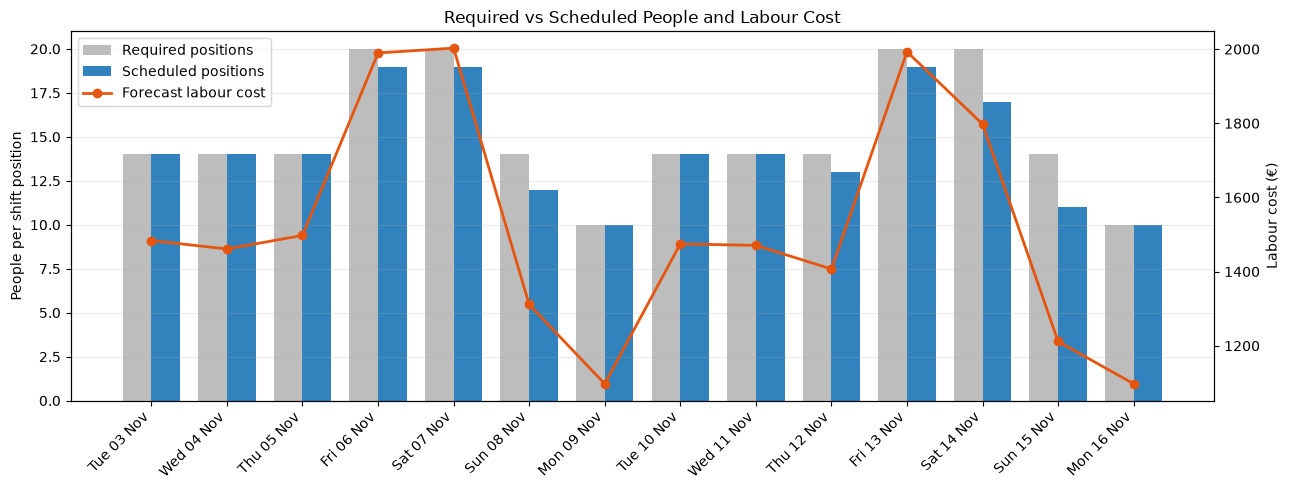

In [58]:
# ============================================================
# REQUIRED VS SCHEDULED PEOPLE AND LABOUR COST
# ============================================================

scheduled_positions = (
    recommended_roster
    .groupby("date")
    .size()
    .rename("scheduled_positions")
)

chart_data = (
    workforce_forecast
    .set_index("date")
    .join(scheduled_positions)
)

chart_data["scheduled_positions"] = (
    chart_data["scheduled_positions"]
    .fillna(0)
)

x = np.arange(len(chart_data))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    x - bar_width / 2,
    chart_data["required_staff"],
    bar_width,
    label="Required positions",
    color="#bdbdbd"
)

ax.bar(
    x + bar_width / 2,
    chart_data["scheduled_positions"],
    bar_width,
    label="Scheduled positions",
    color="#3182bd"
)

ax.set_xticks(x)
ax.set_xticklabels(
    chart_data.index.strftime("%a %d %b"),
    rotation=45,
    ha="right"
)
ax.set_ylabel("People per shift position")
ax.set_title("Required vs Scheduled People and Labour Cost")
ax.grid(axis="y", alpha=0.25)

ax_cost = ax.twinx()
ax_cost.plot(
    x,
    chart_data["labour_cost"],
    color="#e6550d",
    marker="o",
    linewidth=2,
    label="Forecast labour cost"
)
ax_cost.set_ylabel("Labour cost (€)")

handles, labels = ax.get_legend_handles_labels()
cost_handles, cost_labels = ax_cost.get_legend_handles_labels()
ax.legend(
    handles + cost_handles,
    labels + cost_labels,
    loc="upper left"
)

plt.tight_layout()
plt.show()

# 6. Required staffing by role and date

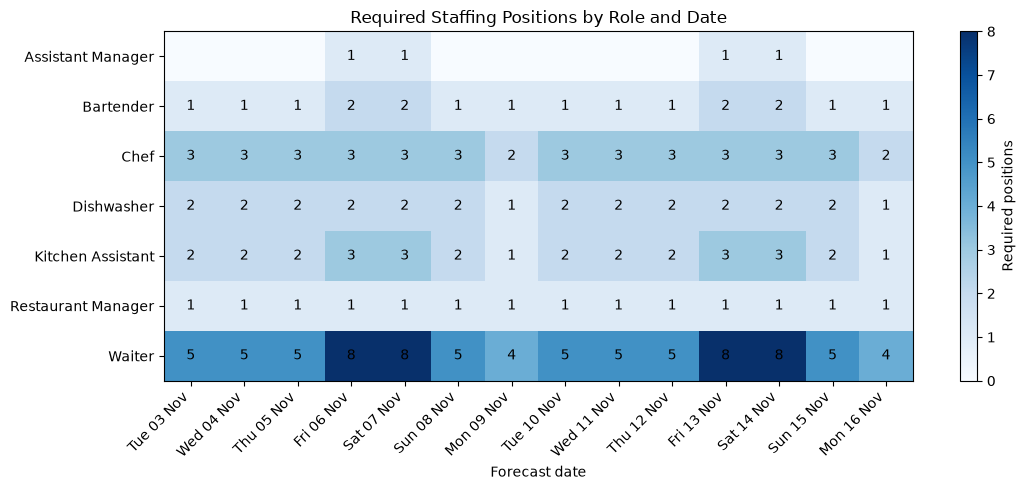

In [59]:
# ============================================================
# REQUIRED POSITIONS BY ROLE AND DATE
# ============================================================

required_role_day = (
    forecast_staffing
    .pivot_table(
        index="role",
        columns="date",
        values="required",
        aggfunc="sum",
        fill_value=0
    )
)

fig, ax = plt.subplots(
    figsize=(max(10, len(required_role_day.columns) * 0.8), 5)
)

image = ax.imshow(
    required_role_day.values,
    aspect="auto",
    cmap="Blues"
)

ax.set_yticks(np.arange(len(required_role_day.index)))
ax.set_yticklabels(required_role_day.index)

ax.set_xticks(np.arange(len(required_role_day.columns)))
ax.set_xticklabels(
    required_role_day.columns.strftime("%a %d %b"),
    rotation=45,
    ha="right"
)

for row in range(required_role_day.shape[0]):
    for col in range(required_role_day.shape[1]):
        value = required_role_day.iloc[row, col]
        if value > 0:
            ax.text(col, row, int(value), ha="center", va="center")

ax.set_title("Required Staffing Positions by Role and Date")
ax.set_xlabel("Forecast date")
fig.colorbar(image, ax=ax, label="Required positions")
plt.tight_layout()
plt.show()

# 7. Recommended roster calendar

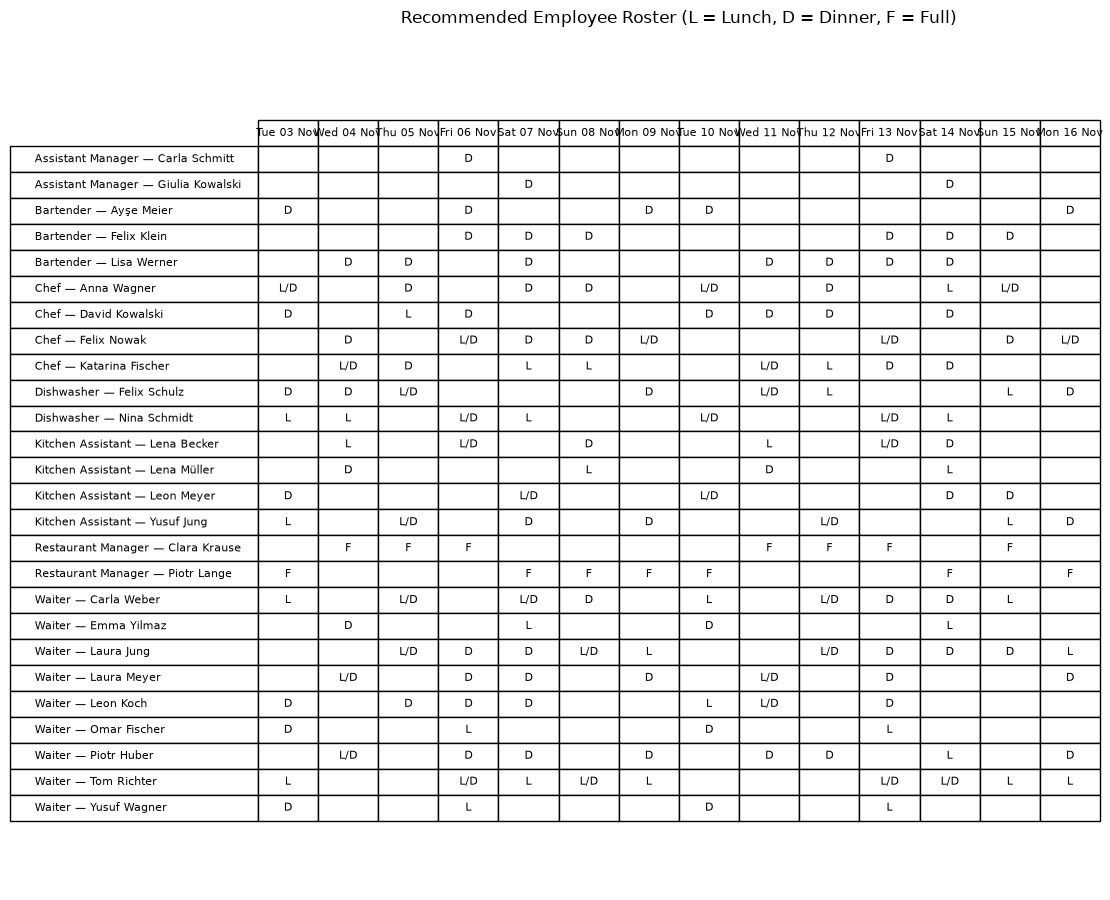

In [60]:
# ============================================================
# RECOMMENDED ROSTER CALENDAR
# ============================================================

roster_calendar_data = recommended_roster.copy()

roster_calendar_data["shift_code"] = (
    roster_calendar_data["shift_type"]
    .map({
        "Lunch": "L",
        "Dinner": "D",
        "Full": "F"
    })
)

roster_calendar_data["employee_label"] = (
    roster_calendar_data["role"]
    + " — "
    + roster_calendar_data["employee_name"]
)

roster_calendar = (
    roster_calendar_data
    .pivot_table(
        index="employee_label",
        columns="date",
        values="shift_code",
        aggfunc=lambda values: "/".join(values)
    )
    .fillna("")
)

fig, ax = plt.subplots(
    figsize=(max(10, len(roster_calendar.columns) * 0.8),
             max(5, len(roster_calendar.index) * 0.35))
)

ax.axis("off")

table = ax.table(
    cellText=roster_calendar.values,
    rowLabels=roster_calendar.index,
    colLabels=roster_calendar.columns.strftime("%a %d %b"),
    loc="center",
    cellLoc="center",
    rowLoc="left"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.3)

ax.set_title(
    "Recommended Employee Roster (L = Lunch, D = Dinner, F = Full)",
    pad=20
)

plt.tight_layout()
plt.show()

# 8. Save the outputs

In [61]:
# ============================================================
# SAVE WORKFORCE OUTPUTS
# ============================================================

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Ensure dates are stored consistently
workforce_forecast["date"] = pd.to_datetime(workforce_forecast["date"])
final_roster["date"] = pd.to_datetime(final_roster["date"])
staffing_coverage["date"] = pd.to_datetime(staffing_coverage["date"])

# Use the actual planning horizon in the filename
workforce_horizon = workforce_forecast["date"].nunique()

workforce_forecast_path = (
    output_dir / f"workforce_forecast_next_{workforce_horizon}_days.csv"
)

roster_path = output_dir / "recommended_roster.csv"
coverage_path = output_dir / "staffing_coverage.csv"

# Save outputs
workforce_forecast.to_csv(workforce_forecast_path, index=False)
final_roster.to_csv(roster_path, index=False)
staffing_coverage.to_csv(coverage_path, index=False)


# ============================================================
# VERIFY SAVED OUTPUTS
# ============================================================

print("Workforce outputs saved successfully.")

print(f"Workforce forecast: {workforce_forecast_path}")
print(f"Recommended roster: {roster_path}")
print(f"Staffing coverage: {coverage_path}")

print(
    "Forecast period:",
    workforce_forecast["date"].min().date(),
    "to",
    workforce_forecast["date"].max().date()
)

print("Forecast days:", workforce_horizon)
print("Recommended roster rows:", len(final_roster))
print("Staffing coverage rows:", len(staffing_coverage))

print("\nWorkforce forecasting pipeline complete.")

Workforce outputs saved successfully.
Workforce forecast: ../outputs/workforce_forecast_next_14_days.csv
Recommended roster: ../outputs/recommended_roster.csv
Staffing coverage: ../outputs/staffing_coverage.csv
Forecast period: 2026-11-03 to 2026-11-16
Forecast days: 14
Recommended roster rows: 200
Staffing coverage rows: 140

Workforce forecasting pipeline complete.


In [62]:
# ============================================================
# WORKFORCE INTELLIGENCE — INTERPRETATION
# ============================================================

under_coverage_days = (
    staffing_coverage
    .groupby("date")["shortfall"]
    .sum()
    .gt(0)
    .sum()
)

print(
    "WORKFORCE INTELLIGENCE CONCLUSION"
)
print("-" * 60)

print(
    f"The workforce planning model converts forecast demand "
    f"into staffing requirements across a {FORECAST_HORIZON}-day horizon."
)

print(
    f"\nExpected orders: {forecast_total_orders:,.0f}"
)

print(
    f"Estimated labour cost: €{forecast_labour_cost:,.2f}"
)

print(
    f"Labour cost as a percentage of forecast revenue: "
    f"{forecast_labour_cost_pct:.2f}%"
)

print(
    f"\nDays with staffing coverage shortfalls: "
    f"{under_coverage_days}"
)

print(
    "\nThe recommended roster respects employee availability "
    "and contractual weekly-hour limits where sufficient eligible "
    "employees are available."
)

WORKFORCE INTELLIGENCE CONCLUSION
------------------------------------------------------------
The workforce planning model converts forecast demand into staffing requirements across a 14-day horizon.

Expected orders: 1,211
Estimated labour cost: €21,295.00
Labour cost as a percentage of forecast revenue: 48.28%

Days with staffing coverage shortfalls: 7

The recommended roster respects employee availability and contractual weekly-hour limits where sufficient eligible employees are available.
